| Nama              | NRP        |
|-------------------|------------|
| Muhammad Dayyan Ghazanfar Latief         | 5054241036     |

<center><strong>Deep Learning : Computer Vision</strong><br />
<strong><font color="blue">Departemen Informatika - Prodi RKA - Institut Teknologi Sepuluh Nopember</font></strong><br />
</center>

<strong>Outline Hands-On: Image Classification with CNN</strong><br />
<li> Pengenalan Computer Vision & Image Classification </li>
<li> Convolutional Neural Network (CNN) </li>
<li> Implementasi CNN sederhana dengan dataset MNIST </li>
<li> Implementasi CNN dengan dataset CIFAR-10 </li>
<li> Mengatasi Overfitting: Dropout & Data Augmentation </li>
<li> Transfer Learning dengan Pre-trained Model </li>
<li> Fine-Tuning Pre-trained Model </li>

---

## Setup & Persiapan Environment

<p><strong><font color="red">PENTING:</font></strong> Pastikan runtime Google Colab menggunakan <strong>GPU</strong> untuk mempercepat proses training.</p>

<p>Cara mengaktifkan GPU di Google Colab:</p>
<ol>
    <li>Klik menu <strong>Runtime</strong> → <strong>Change runtime type</strong></li>
    <li>Pada <strong>Hardware accelerator</strong>, pilih <strong>GPU (T4)</strong></li>
    <li>Klik <strong>Save</strong></li>
</ol>

In [1]:
# Import library yang dibutuhkan
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

2026-04-08 03:58:13.804880: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775620694.238993      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775620694.364010      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775620695.360642      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775620695.360689      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775620695.360692      55 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


---
## 1. Pengenalan Computer Vision & Image Classification

<p><strong>Computer Vision</strong> adalah cabang dari Artificial Intelligence yang memungkinkan komputer untuk <em>meniru kemampuan manusia</em> dalam melihat dan memahami informasi visual.</p>

<p>Beberapa task utama dalam Computer Vision:</p>
<ul>
    <li><strong>Image Classification</strong> — Menentukan kategori/kelas dari suatu gambar (contoh: gambar kucing atau anjing)</li>
    <li><strong>Object Detection</strong> — Mendeteksi dan melokalisasi objek dalam gambar dengan bounding box</li>
    <li><strong>Instance Segmentation</strong> — Segmentasi piksel per-objek secara individual</li>
    <li><strong>Image Captioning</strong> — Menghasilkan deskripsi teks dari gambar</li>
</ul>

<p>Pada hands-on ini kita akan fokus pada <strong>Image Classification</strong>.</p>

### Machine Learning vs Deep Learning untuk Image Classification

<p>Ada dua pendekatan utama:</p>

<table border="1" cellpadding="8" cellspacing="0">
<tr><th></th><th><strong>Machine Learning (Tradisional)</strong></th><th><strong>Deep Learning (CNN)</strong></th></tr>
<tr><td><strong>Feature Extraction</strong></td><td>Manual/Hand-crafted (HOG, LBP, GLCM, dll)</td><td>Otomatis dipelajari oleh model</td></tr>
<tr><td><strong>Pipeline</strong></td><td>Feature Extraction → Classifier terpisah</td><td>End-to-end (extraction + classification sekaligus)</td></tr>
<tr><td><strong>Data</strong></td><td>Bisa bekerja dengan data kecil</td><td>Butuh data besar untuk performa optimal</td></tr>
<tr><td><strong>Performa</strong></td><td>Baik untuk domain spesifik</td><td>Umumnya lebih unggul di berbagai task</td></tr>
</table>

---
## 2. Convolutional Neural Network (CNN)

<p><strong>CNN (Convolutional Neural Network)</strong> adalah arsitektur neural network yang dirancang khusus untuk memproses data visual. CNN belajar <strong>pola lokal</strong> (local patterns) dari gambar, berbeda dengan Feedforward NN yang belajar pola global.</p>

<p><strong>Karakteristik utama CNN:</strong></p>
<ul>
    <li><strong>Translation Invariant</strong> — Pola yang dipelajari tidak bergantung pada posisi di gambar</li>
    <li><strong>Spatial Hierarchy</strong> — CNN dapat mempelajari hierarki pola, dari fitur sederhana (edge, texture) ke fitur kompleks (objek, wajah)</li>
</ul>

### Komponen Utama Arsitektur CNN:

<ol>
    <li><strong>Convolutional Layer</strong> — Filter/kernel yang melakukan sliding pada gambar untuk mendeteksi fitur</li>
    <li><strong>Activation Layer (ReLU)</strong> — Menambahkan non-linearitas</li>
    <li><strong>Pooling Layer</strong> — Mengurangi dimensi (downsampling) dan mengekstrak fitur dominan</li>
    <li><strong>Dropout Layer</strong> — Regularisasi untuk mencegah overfitting</li>
    <li><strong>Fully Connected (Dense) Layer</strong> — Layer klasifikasi di bagian akhir</li>
</ol>

### Operasi Konvolusi

<p>Konvolusi adalah proses menggeser (<em>sliding</em>) sebuah filter/kernel di atas gambar. Filter berperan sebagai <strong>feature detector</strong>.</p>

<p><strong>Rumus ukuran output:</strong></p>
<p style="text-align:center; font-size:16px;"><code>Output Size = (N - F) / S + 1</code></p>
<p>Dimana: N = ukuran input, F = ukuran filter, S = stride</p>

<p><strong>Padding:</strong></p>
<ul>
    <li><strong>Valid padding</strong> — Tidak ada padding, ukuran output mengecil</li>
    <li><strong>Same padding</strong> — Ditambahkan zero padding agar ukuran output = ukuran input</li>
</ul>

<p><strong>Pooling Layer:</strong> Bertujuan untuk mengurangi dimensi dan mengekstrak fitur dominan. Tipe yang umum: <strong>Max Pooling</strong> (mengambil nilai maksimum) dan <strong>Average Pooling</strong>.</p>

Mari kita lihat bagaimana konvolusi bekerja secara visual:

In [2]:
# Demonstrasi operasi konvolusi sederhana
import numpy as np

# Contoh gambar 5x5
image = np.array([
    [1, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 1, 1],
    [0, 0, 1, 1, 0],
    [0, 1, 1, 0, 0]
])

# Filter 3x3 (edge detector)
filter_kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

# Konvolusi manual (valid padding, stride=1)
output_size = image.shape[0] - filter_kernel.shape[0] + 1  # (5-3)/1 + 1 = 3
output = np.zeros((output_size, output_size))

for i in range(output_size):
    for j in range(output_size):
        region = image[i:i+3, j:j+3]
        output[i, j] = np.sum(region * filter_kernel)

print("Input Image (5x5):")
print(image)
print(f"\nFilter (3x3):")
print(filter_kernel)
print(f"\nOutput (3x3):")
print(output)
print(f"\nOutput size: ({output_size}x{output_size}) = (N-F)/S + 1 = (5-3)/1 + 1 = 3")

Input Image (5x5):
[[1 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 1 1]
 [0 0 1 1 0]
 [0 1 1 0 0]]

Filter (3x3):
[[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]

Output (3x3):
[[-2.  0.  2.]
 [-3. -2.  2.]
 [-3. -1.  2.]]

Output size: (3x3) = (N-F)/S + 1 = (5-3)/1 + 1 = 3


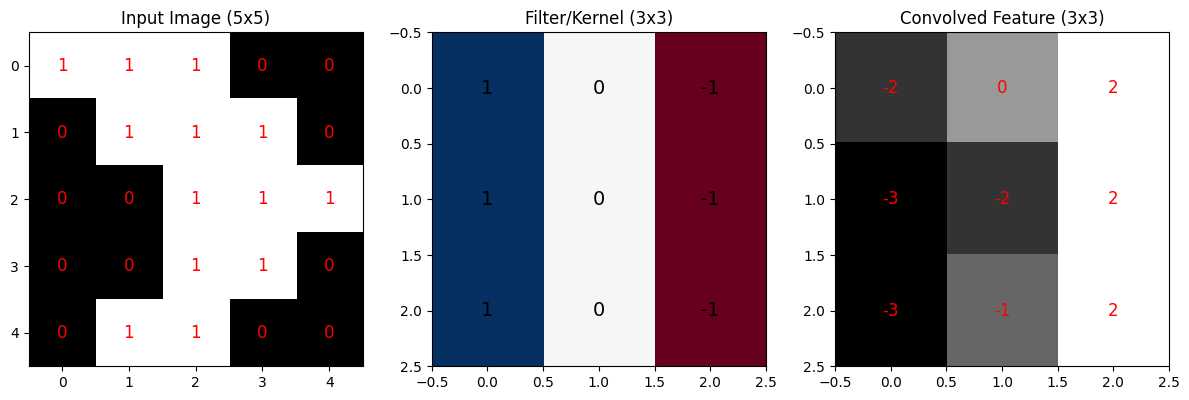

In [3]:
# Visualisasi konvolusi
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image, cmap='gray')
axes[0].set_title('Input Image (5x5)', fontsize=12)
for i in range(5):
    for j in range(5):
        axes[0].text(j, i, str(image[i,j]), ha='center', va='center', color='red', fontsize=12)

axes[1].imshow(filter_kernel, cmap='RdBu')
axes[1].set_title('Filter/Kernel (3x3)', fontsize=12)
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, str(filter_kernel[i,j]), ha='center', va='center', color='black', fontsize=14)

axes[2].imshow(output, cmap='gray')
axes[2].set_title('Convolved Feature (3x3)', fontsize=12)
for i in range(3):
    for j in range(3):
        axes[2].text(j, i, str(int(output[i,j])), ha='center', va='center', color='red', fontsize=12)

plt.tight_layout()
plt.show()

<h3><font color="blue">Latihan 1:</font></h3>

<ul>
    <li>Ubah filter menjadi horizontal edge detector: <code>[[1,1,1],[0,0,0],[-1,-1,-1]]</code>. Apa perbedaan hasilnya?</li>
    <li>Apa yang terjadi jika stride diubah menjadi 2? Hitung ukuran output secara manual terlebih dahulu.</li>
</ul>

In [4]:
# Kerjakan Latihan 1 pada cell berikut ini

# Contoh gambar 5x5
image = np.array([
    [1, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 1, 1],
    [0, 0, 1, 1, 0],
    [0, 1, 1, 0, 0]
])

# Filter 3x3 (Horizontal Edge Detector)
filter_kernel = np.array([
    [1, 1, 1],
    [0, 0, 0],
    [-1, -1, -1]
])

# Konfigurasi Stride
S = 2
N = image.shape[0]
F = filter_kernel.shape[0]

# Konvolusi manual (valid padding) dengan Stride = 2
output_size = ((N - F) // S) + 1  # (5-3)/2 + 1 = 2
output = np.zeros((output_size, output_size))

for i in range(output_size):
    for j in range(output_size):
        row_start = i * S
        col_start = j * S
        region = image[row_start:row_start+F, col_start:col_start+F]
        output[i, j] = np.sum(region * filter_kernel)

print("Input Image (5x5):")
print(image)
print(f"\nFilter (3x3) - Horizontal Edge Detector:")
print(filter_kernel)
print(f"\nOutput ({output_size}x{output_size}) dengan Stride {S}:")
print(output)

Input Image (5x5):
[[1 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 1 1]
 [0 0 1 1 0]
 [0 1 1 0 0]]

Filter (3x3) - Horizontal Edge Detector:
[[ 1  1  1]
 [ 0  0  0]
 [-1 -1 -1]]

Output (2x2) dengan Stride 2:
[[ 2. -2.]
 [-1.  2.]]


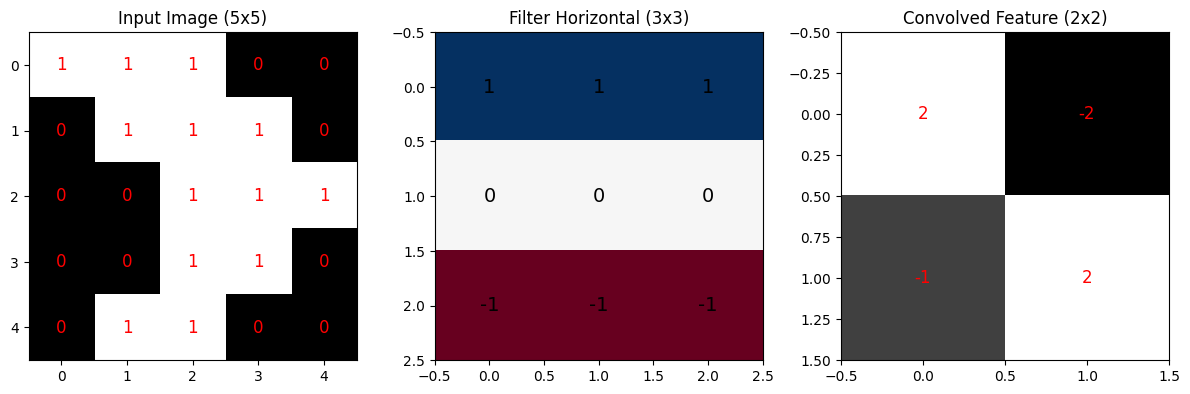

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image, cmap='gray')
axes[0].set_title('Input Image (5x5)', fontsize=12)
for i in range(5):
    for j in range(5):
        axes[0].text(j, i, str(image[i,j]), ha='center', va='center', color='red', fontsize=12)

axes[1].imshow(filter_kernel, cmap='RdBu')
axes[1].set_title('Filter Horizontal (3x3)', fontsize=12)
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, str(filter_kernel[i,j]), ha='center', va='center', color='black', fontsize=14)

axes[2].imshow(output, cmap='gray')
axes[2].set_title(f'Convolved Feature ({output_size}x{output_size})', fontsize=12)
for i in range(output_size):
    for j in range(output_size):
        axes[2].text(j, i, str(int(output[i,j])), ha='center', va='center', color='red', fontsize=12)

plt.tight_layout()
plt.show()

In [6]:
print("\n=== Kesimpulan Latihan 1 ===")
print("- Efek Perubahan Filter: Filter yang baru berfungsi sebagai pendeteksi tepi horizontal (mendatar), kebalikan dari filter sebelumnya yang mendeteksi tepi vertikal.")
print("- Efek Perubahan Stride: Mengubah stride menjadi 2 membuat filter bergeser sejauh 2 piksel sekaligus. Akibatnya, terjadi downsampling yang memperkecil ukuran matriks output dari 3x3 menjadi 2x2.")


=== Kesimpulan Latihan 1 ===
- Efek Perubahan Filter: Filter yang baru berfungsi sebagai pendeteksi tepi horizontal (mendatar), kebalikan dari filter sebelumnya yang mendeteksi tepi vertikal.
- Efek Perubahan Stride: Mengubah stride menjadi 2 membuat filter bergeser sejauh 2 piksel sekaligus. Akibatnya, terjadi downsampling yang memperkecil ukuran matriks output dari 3x3 menjadi 2x2.


---
## 3. CNN untuk Klasifikasi MNIST

<p>Dataset <strong>MNIST</strong> berisi gambar tulisan tangan angka 0-9. Setiap gambar berukuran 28×28 piksel (grayscale).</p>

<ul>
    <li>60.000 data training</li>
    <li>10.000 data testing</li>
    <li>10 kelas (angka 0-9)</li>
</ul>

<p>Arsitektur CNN yang akan kita bangun:</p>
<p><code>Input(28x28x1) → Conv2D(16) → MaxPool → Conv2D(32) → MaxPool → Flatten → Dense(64) → Output(10, softmax)</code></p>

In [24]:
# Load dataset MNIST
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")
print(f"Jumlah kelas: {len(np.unique(y_train))}")
print(f"Label unik: {np.unique(y_train)}")

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Jumlah kelas: 10
Label unik: [0 1 2 3 4 5 6 7 8 9]


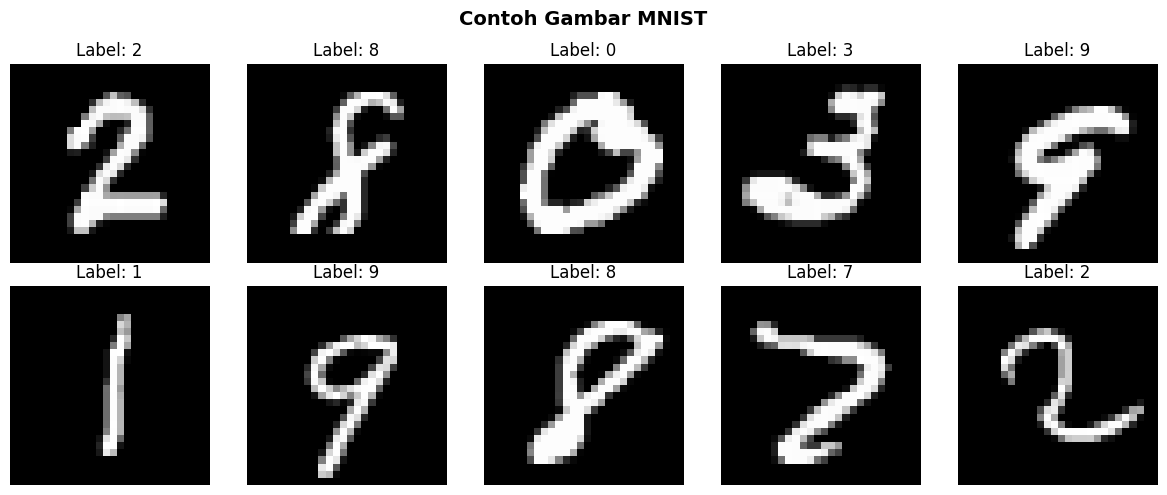

In [25]:
# Visualisasi beberapa contoh gambar
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flatten()):
    idx = np.random.randint(0, X_train.shape[0])
    ax.imshow(X_train[idx], cmap='gray')
    ax.set_title(f'Label: {y_train[idx]}', fontsize=12)
    ax.axis('off')
plt.suptitle('Contoh Gambar MNIST', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [26]:
# Preprocessing
# 1. Reshape: tambahkan dimensi channel (28,28) -> (28,28,1)
X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype('float32')
X_test_cnn = X_test.reshape(-1, 28, 28, 1).astype('float32')

# 2. Normalisasi piksel dari [0, 255] ke [0, 1]
X_train_cnn = X_train_cnn / 255.0
X_test_cnn = X_test_cnn / 255.0

# 3. One-hot encoding untuk label
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print(f"Shape setelah preprocessing: {X_train_cnn.shape}")
print(f"Contoh label one-hot (angka {y_train[0]}): {y_train_cat[0]}")

Shape setelah preprocessing: (60000, 28, 28, 1)
Contoh label one-hot (angka 5): [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [27]:
# Membangun model CNN untuk MNIST
model_mnist = Sequential([
    # Convolutional Block 1
    Conv2D(16, (3,3), activation='relu', input_shape=(28,28,1), padding='same'),
    MaxPooling2D(2,2),

    # Convolutional Block 2
    Conv2D(32, (3,3), activation='relu', padding='same'),
    MaxPooling2D(2,2),

    # Classifier
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model_mnist.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,866 (413.54 KB)

 Trainable params: 105,866 (413.54 KB)

 Non-trainable params: 0 (0.00 B)

<p><strong>Penjelasan arsitektur:</strong></p>
<ul>
    <li><strong>Conv2D(16, (3,3))</strong> — 16 filter berukuran 3×3, dengan same padding agar ukuran output tetap 28×28</li>
    <li><strong>MaxPooling2D(2,2)</strong> — Mengurangi dimensi menjadi setengahnya (28×28 → 14×14)</li>
    <li><strong>Conv2D(32, (3,3))</strong> — 32 filter berukuran 3×3, output 14×14</li>
    <li><strong>MaxPooling2D(2,2)</strong> — Mengurangi lagi (14×14 → 7×7)</li>
    <li><strong>Flatten()</strong> — Mengubah tensor 3D menjadi 1D (7×7×32 = 1568)</li>
    <li><strong>Dense(64)</strong> — Fully connected layer dengan 64 neuron</li>
    <li><strong>Dense(10, softmax)</strong> — Output layer untuk 10 kelas</li>
</ul>

In [28]:
# Compile dan training model
model_mnist.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_mnist = model_mnist.fit(
    X_train_cnn, y_train_cat,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8545 - loss: 0.4893 - val_accuracy: 0.9810 - val_loss: 0.0648
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9790 - loss: 0.0681 - val_accuracy: 0.9857 - val_loss: 0.0505
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9871 - loss: 0.0438 - val_accuracy: 0.9880 - val_loss: 0.0413
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9892 - loss: 0.0329 - val_accuracy: 0.9888 - val_loss: 0.0412
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9916 - loss: 0.0247 - val_accuracy: 0.9897 - val_loss: 0.0417


In [29]:
# Evaluasi model pada data test
test_loss, test_acc = model_mnist.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 0.9854
Test Loss: 0.0409


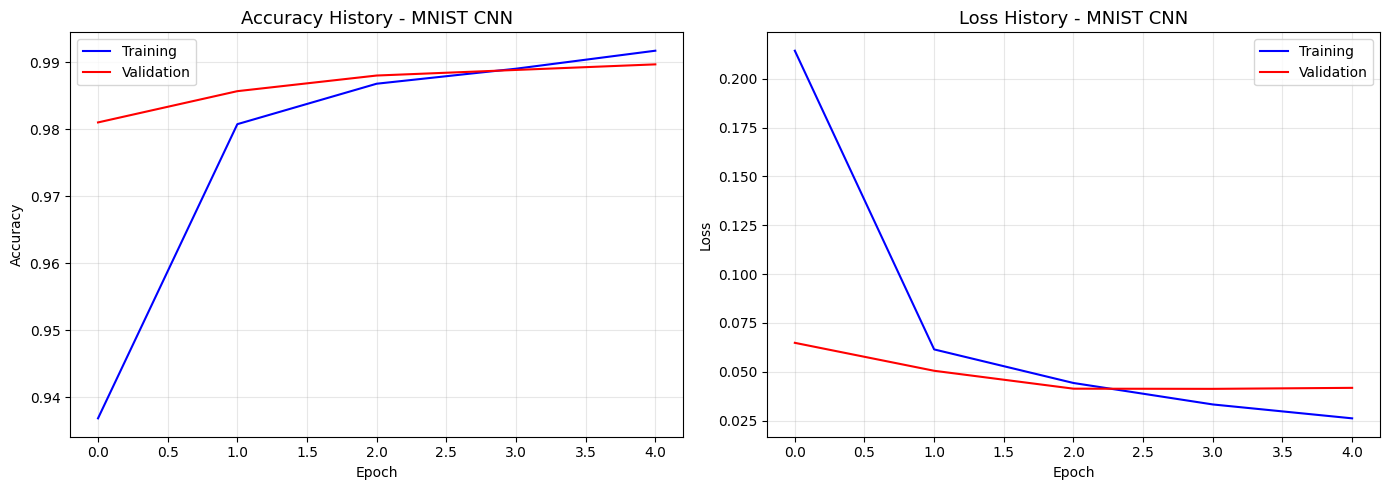

In [30]:
# Fungsi untuk memplot training history
def plot_history(history, title=''):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy
    ax1.plot(history.history['accuracy'], 'b-', label='Training')
    ax1.plot(history.history['val_accuracy'], 'r-', label='Validation')
    ax1.set_title(f'Accuracy History {title}', fontsize=13)
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Loss
    ax2.plot(history.history['loss'], 'b-', label='Training')
    ax2.plot(history.history['val_loss'], 'r-', label='Validation')
    ax2.set_title(f'Loss History {title}', fontsize=13)
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history_mnist, '- MNIST CNN')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step


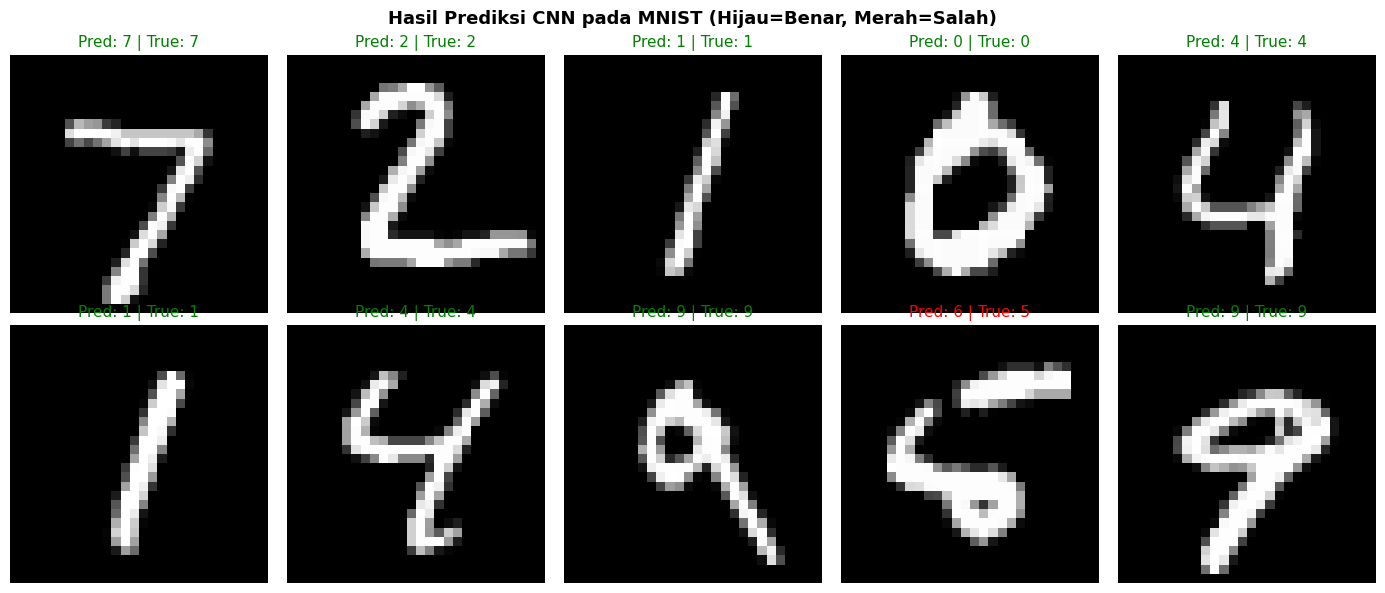

In [31]:
# Visualisasi prediksi
predictions = model_mnist.predict(X_test_cnn[:10])

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_test[i], cmap='gray')
    pred_label = np.argmax(predictions[i])
    true_label = y_test[i]
    color = 'green' if pred_label == true_label else 'red'
    ax.set_title(f'Pred: {pred_label} | True: {true_label}',
                 color=color, fontsize=11)
    ax.axis('off')
plt.suptitle('Hasil Prediksi CNN pada MNIST (Hijau=Benar, Merah=Salah)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

<h3><font color="blue">Latihan 2:</font></h3>

<ul>
    <li>Ganti dataset MNIST dengan <strong>Fashion-MNIST</strong> (<code>tensorflow.keras.datasets.fashion_mnist</code>). Apa perbedaan hasilnya? Mengapa?</li>
    <li>Coba tambahkan 1 convolutional block lagi (Conv2D + MaxPooling). Apakah akurasi meningkat?</li>
    <li>Berapa jumlah total parameter pada model yang telah ditambahkan?</li>
</ul>

<p><strong>Hint:</strong> Fashion-MNIST memiliki dimensi dan jumlah data yang sama dengan MNIST, tetapi berisi gambar item fashion (baju, sepatu, tas, dll.) sehingga lebih menantang.</p>

In [32]:
# Kerjakan Latihan 2 pada cell berikut ini
from tensorflow.keras.datasets import fashion_mnist

(X_train_fm, y_train_fm), (X_test_fm, y_test_fm) = fashion_mnist.load_data()

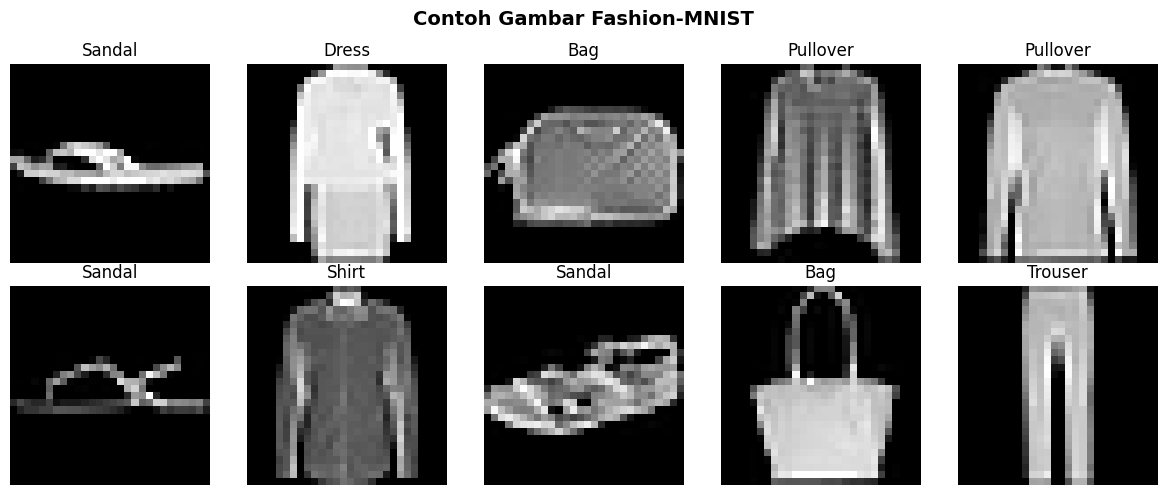

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Daftar nama kelas pada Fashion-MNIST
class_names_fm = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
                  'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Visualisasi 10 contoh gambar secara acak
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flatten()):
    # Mengambil index acak dari data training
    idx = np.random.randint(0, X_train_fm.shape[0])

    # Menampilkan gambar (menggunakan colormap gray)
    ax.imshow(X_train_fm[idx], cmap='gray')

    # Menampilkan nama pakaian berdasarkan label angkanya
    label_idx = y_train_fm[idx]
    ax.set_title(f'{class_names_fm[label_idx]}', fontsize=12)
    ax.axis('off')

plt.suptitle('Contoh Gambar Fashion-MNIST', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [34]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical

# Preprocessing
X_train_fm_cnn = X_train_fm.reshape(-1, 28, 28, 1).astype('float32') / 255.0
X_test_fm_cnn = X_test_fm.reshape(-1, 28, 28, 1).astype('float32') / 255.0

y_train_fm_cat = to_categorical(y_train_fm, 10)
y_test_fm_cat = to_categorical(y_test_fm, 10)

# Membangun model CNN baru 
model_fm = Sequential([
    # Convolutional Block 1
    Conv2D(16, (3,3), activation='relu', input_shape=(28,28,1), padding='same'),
    MaxPooling2D(2,2),

    # Convolutional Block 2
    Conv2D(32, (3,3), activation='relu', padding='same'),
    MaxPooling2D(2,2),

    # Convolutional Block 3 (Tambahan Baru)
    Conv2D(64, (3,3), activation='relu', padding='same'),
    MaxPooling2D(2,2),

    # Classifier
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

print("Summary Model Fashion-MNIST:")
model_fm.summary()

Summary Model Fashion-MNIST:


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,874 (237.79 KB)

 Trainable params: 60,874 (237.79 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
# Compile dan Training
model_fm.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("\nTraining Model Fashion-MNIST...")
history_fm = model_fm.fit(X_train_fm_cnn, y_train_fm_cat, epochs=5, batch_size=64, validation_split=0.1, verbose=1)

# Evaluasi Model
test_loss_fm, test_acc_fm = model_fm.evaluate(X_test_fm_cnn, y_test_fm_cat, verbose=0)

# Visualisasi prediksi
predictions = model_fm.predict(X_test_cnn[:10])


Training Model Fashion-MNIST...
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9415 - loss: 0.1583 - val_accuracy: 0.9133 - val_loss: 0.2383
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9488 - loss: 0.1397 - val_accuracy: 0.9155 - val_loss: 0.2330
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9525 - loss: 0.1299 - val_accuracy: 0.9152 - val_loss: 0.2704
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9546 - loss: 0.1252 - val_accuracy: 0.9085 - val_loss: 0.2722
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9592 - loss: 0.1102 - val_accuracy: 0.9192 - val_loss: 0.2451
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step


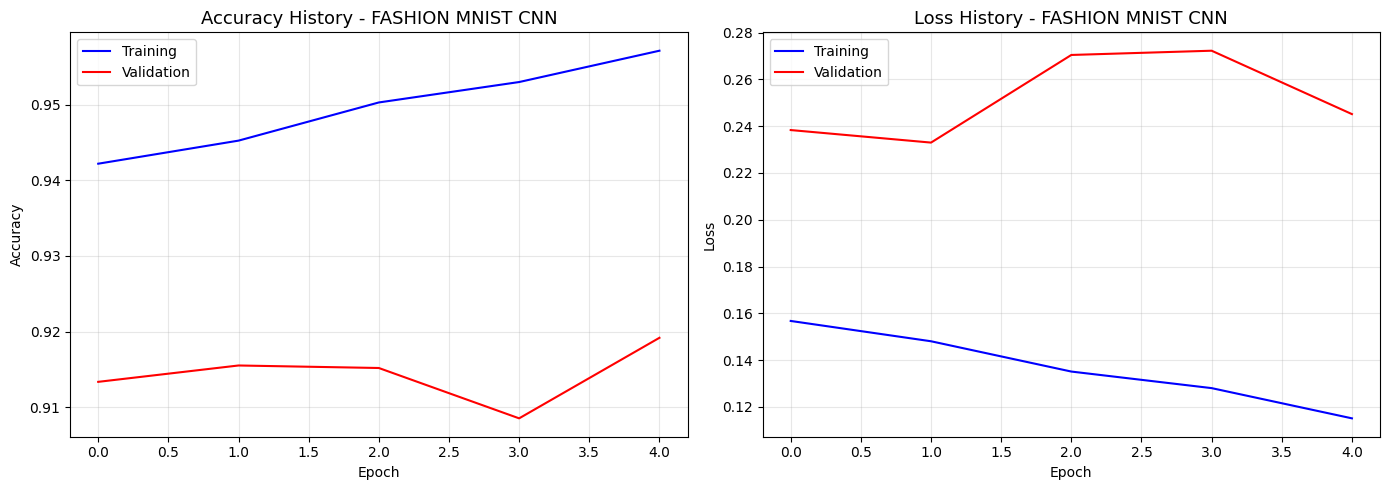

In [44]:
plot_history(history_fm, '- FASHION MNIST CNN')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


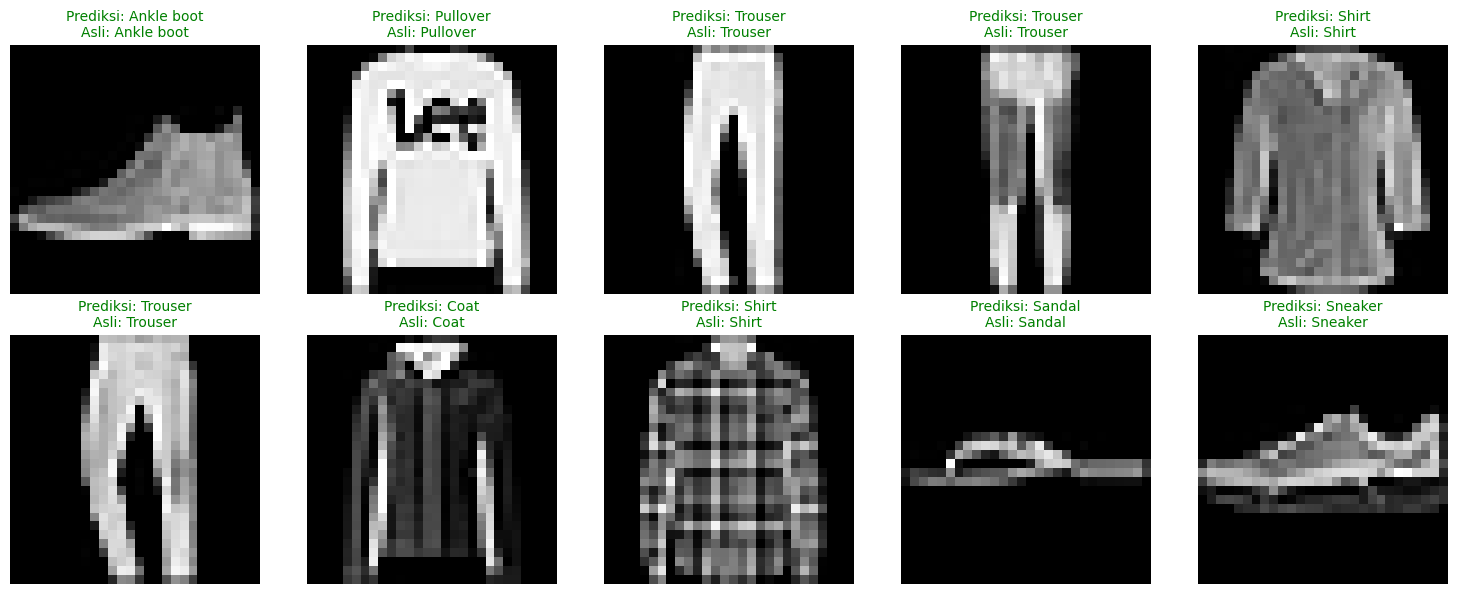

In [45]:
import matplotlib.pyplot as plt
import numpy as np

class_names_fm = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
                  'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

predictions_fm = model_fm.predict(X_test_fm_cnn)

predicted_labels = np.argmax(predictions_fm, axis=1)
true_labels = np.argmax(y_test_fm_cat, axis=1) 

plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    
    img = X_test_fm_cnn[i].reshape(28, 28)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    
    pred_class = class_names_fm[predicted_labels[i]]
    true_class = class_names_fm[true_labels[i]]
    
    color = 'green' if predicted_labels[i] == true_labels[i] else 'red'
    
    plt.title(f"Prediksi: {pred_class}\nAsli: {true_class}", color=color, fontsize=10)

plt.tight_layout()
plt.show()

In [46]:
print("\n=== Kesimpulan Latihan 2 ===")
print(f"- Test Accuracy Fashion-MNIST: {test_acc_fm:.4f}")
print("- Perbedaan Hasil: Akurasi Fashion-MNIST biasanya lebih rendah dibandingkan MNIST. Alasannya, gambar pakaian/barang (Fashion-MNIST) memiliki bentuk, tekstur, dan detail visual yang jauh lebih kompleks dibandingkan sekadar garis sederhana pada angka (MNIST).")
print("- Efek Tambah Block Conv: Menambah layer konvolusi dan pooling membantu model mengekstrak fitur tingkat lanjut (high-level features). Hal ini sangat berguna dan berpotensi meningkatkan performa akurasi pada dataset yang lebih sulit seperti Fashion-MNIST.")
print(f"- Total Parameter Model: Model ini memiliki total {model_fm.count_params()} parameter.")


=== Kesimpulan Latihan 2 ===
- Test Accuracy Fashion-MNIST: 0.9098
- Perbedaan Hasil: Akurasi Fashion-MNIST biasanya lebih rendah dibandingkan MNIST. Alasannya, gambar pakaian/barang (Fashion-MNIST) memiliki bentuk, tekstur, dan detail visual yang jauh lebih kompleks dibandingkan sekadar garis sederhana pada angka (MNIST).
- Efek Tambah Block Conv: Menambah layer konvolusi dan pooling membantu model mengekstrak fitur tingkat lanjut (high-level features). Hal ini sangat berguna dan berpotensi meningkatkan performa akurasi pada dataset yang lebih sulit seperti Fashion-MNIST.
- Total Parameter Model: Model ini memiliki total 60874 parameter.


---
## 4. CNN untuk CIFAR-10 (RGB Images)

<p>Sekarang kita akan mengklasifikasikan gambar berwarna (RGB) menggunakan dataset <strong>CIFAR-10</strong>:</p>
<ul>
    <li>50.000 data training, 10.000 data testing</li>
    <li>Gambar berukuran <strong>32×32 piksel × 3 channel (RGB)</strong></li>
    <li>10 kelas: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck</li>
</ul>

<p>Tantangan: gambar CIFAR-10 berukuran kecil dan lebih kompleks dari MNIST.</p>

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Training shape: (50000, 32, 32, 3)
Testing shape: (10000, 32, 32, 3)


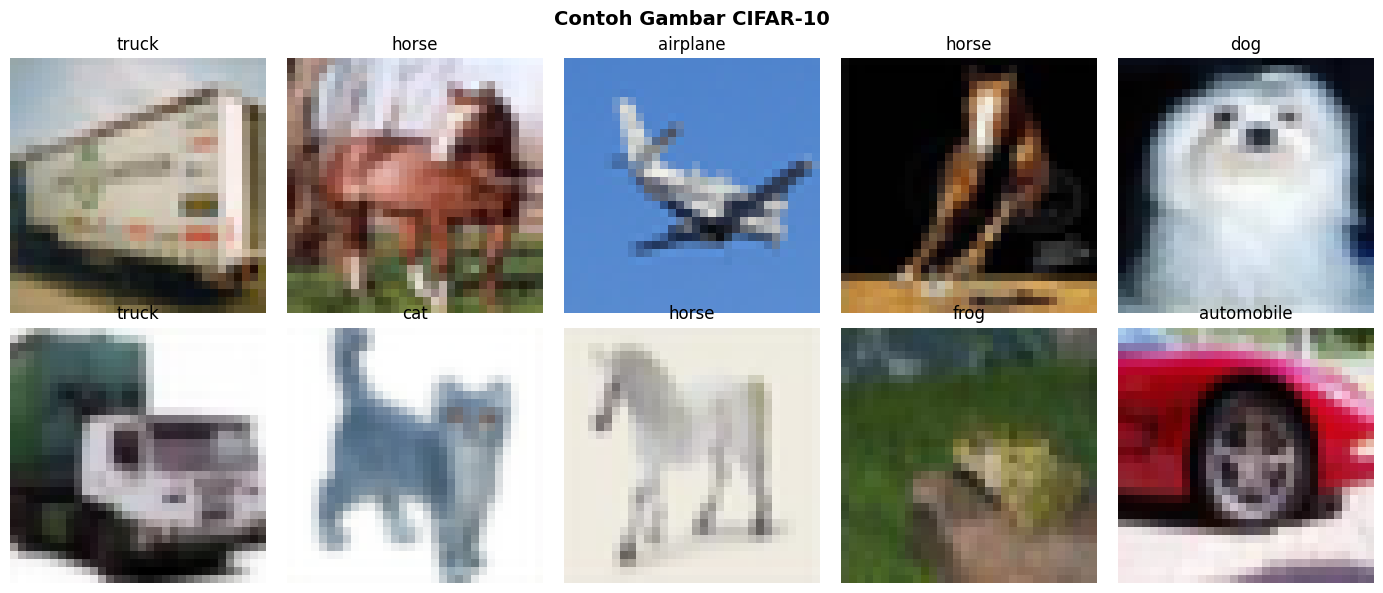

In [47]:
# Load CIFAR-10
from tensorflow.keras.datasets import cifar10

(X_train_cifar, y_train_cifar), (X_test_cifar, y_test_cifar) = cifar10.load_data()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print(f"Training shape: {X_train_cifar.shape}")
print(f"Testing shape: {X_test_cifar.shape}")

# Visualisasi
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flatten()):
    idx = np.random.randint(0, X_train_cifar.shape[0])
    ax.imshow(X_train_cifar[idx])
    ax.set_title(f'{class_names[y_train_cifar[idx][0]]}', fontsize=12)
    ax.axis('off')
plt.suptitle('Contoh Gambar CIFAR-10', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [48]:
# Preprocessing CIFAR-10
X_train_c = X_train_cifar.astype('float32') / 255.0
X_test_c = X_test_cifar.astype('float32') / 255.0

y_train_c = to_categorical(y_train_cifar, 10)
y_test_c = to_categorical(y_test_cifar, 10)

print(f"Shape: {X_train_c.shape}, dtype: {X_train_c.dtype}")

Shape: (50000, 32, 32, 3), dtype: float32


In [49]:
# CNN model untuk CIFAR-10 (tanpa regularisasi)
model_cifar = Sequential([
    # Block 1
    Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3), padding='same'),
    MaxPooling2D(2,2),

    # Block 2
    Conv2D(64, (3,3), activation='relu', padding='same'),
    MaxPooling2D(2,2),

    # Block 3
    Conv2D(128, (3,3), activation='relu', padding='same'),
    MaxPooling2D(2,2),

    # Classifier
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model_cifar.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_16 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [50]:
# Training model CIFAR-10 (tanpa regularisasi)
model_cifar.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_cifar = model_cifar.fit(
    X_train_c, y_train_c,
    epochs=15,
    batch_size=64,
    validation_data=(X_test_c, y_test_c),
    verbose=1
)

# Evaluasi
test_loss, test_acc = model_cifar.evaluate(X_test_c, y_test_c, verbose=0)
print(f"\nTest Accuracy: {test_acc:.4f}")

Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.3610 - loss: 1.7359 - val_accuracy: 0.5996 - val_loss: 1.1374
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.6175 - loss: 1.0862 - val_accuracy: 0.6707 - val_loss: 0.9361
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6941 - loss: 0.8710 - val_accuracy: 0.7055 - val_loss: 0.8466
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7326 - loss: 0.7601 - val_accuracy: 0.7170 - val_loss: 0.8068
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7720 - loss: 0.6545 - val_accuracy: 0.7245 - val_loss: 0.7820
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8008 - loss: 0.5736 - val_accuracy: 0.7428 - val_loss: 0.7497
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8215 - loss: 0.5136 - val_accuracy: 0.7375 - val_loss: 0.8087
Epoch 8/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8438 - loss: 0.4481 - val_accuracy: 0

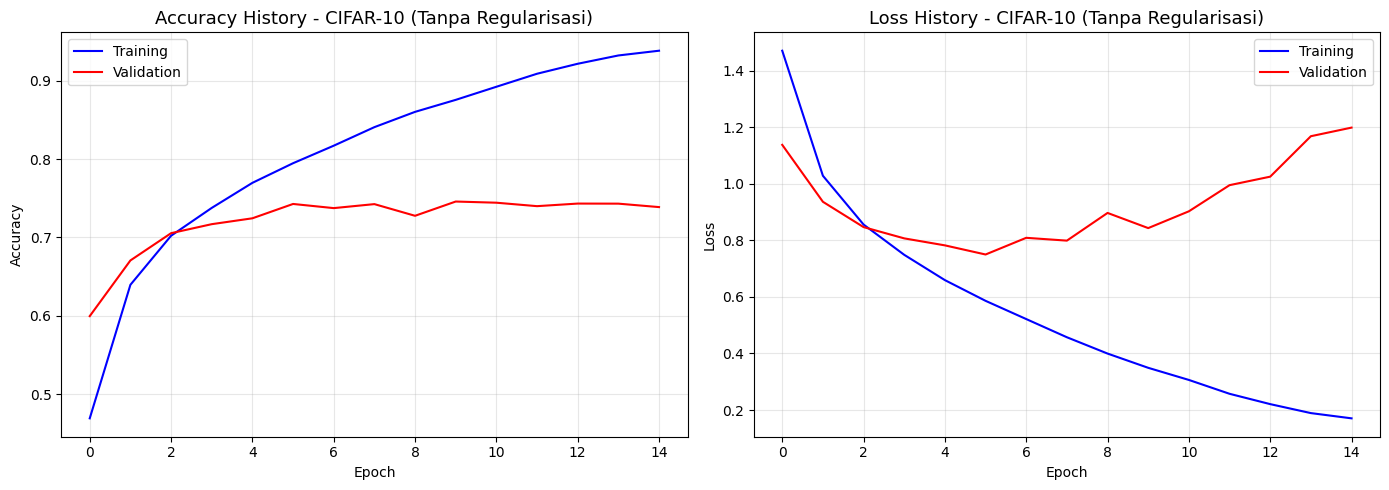

In [51]:
plot_history(history_cifar, '- CIFAR-10 (Tanpa Regularisasi)')

---
## 5. Mengatasi Overfitting

<p>Perhatikan grafik di atas. Jika <strong>training accuracy terus naik</strong> sementara <strong>validation accuracy stagnan/turun</strong>, maka model mengalami <strong>overfitting</strong>.</p>

<p><strong>Solusi Overfitting:</strong></p>
<ol>
    <li><strong>Dropout</strong> — Secara acak menonaktifkan sejumlah neuron selama training untuk mencegah model terlalu bergantung pada fitur tertentu</li>
    <li><strong>Data Augmentation</strong> — Memperbanyak variasi data training dengan transformasi (rotasi, flip, zoom, shift, dll.)</li>
    <li><strong>Menambah data training</strong></li>
    <li><strong>Early Stopping</strong> — Menghentikan training saat validation loss mulai meningkat</li>
</ol>

In [52]:
# CNN model CIFAR-10 DENGAN Dropout
model_cifar_v2 = Sequential([
    # Block 1
    Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3), padding='same'),
    MaxPooling2D(2,2),
    Dropout(0.25),

    # Block 2
    Conv2D(64, (3,3), activation='relu', padding='same'),
    MaxPooling2D(2,2),
    Dropout(0.25),

    # Block 3
    Conv2D(128, (3,3), activation='relu', padding='same'),
    MaxPooling2D(2,2),
    Dropout(0.25),

    # Classifier
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

print("Model dengan Dropout:")
model_cifar_v2.summary()

Model dengan Dropout:


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_19 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

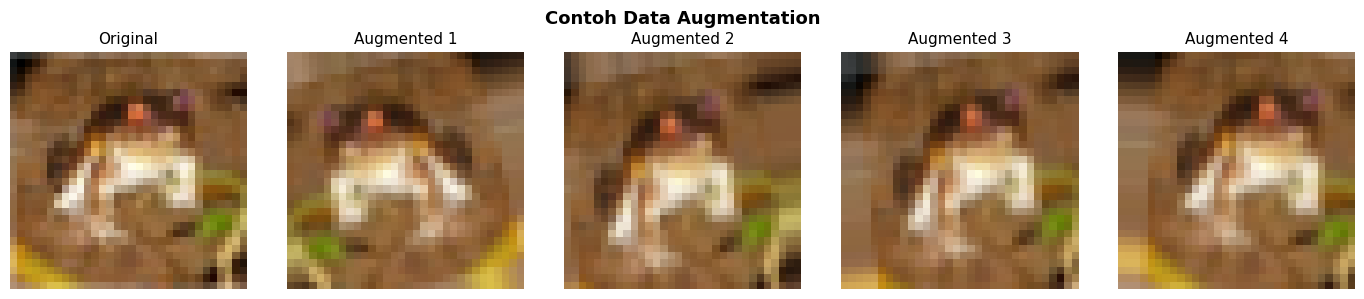

In [53]:
# Data Augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Konfigurasi augmentasi untuk data training
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1
)

# Visualisasi Data Augmentation
sample_img = X_train_c[0:1]  # ambil 1 gambar
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(sample_img[0])
axes[0].set_title('Original', fontsize=11)
axes[0].axis('off')

aug_iter = train_datagen.flow(sample_img, batch_size=1)
for i in range(1, 5):
    aug_img = next(aug_iter)[0]
    axes[i].imshow(aug_img)
    axes[i].set_title(f'Augmented {i}', fontsize=11)
    axes[i].axis('off')

plt.suptitle('Contoh Data Augmentation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [54]:
# Training dengan Dropout + Data Augmentation
model_cifar_v2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_cifar_v2 = model_cifar_v2.fit(
    train_datagen.flow(X_train_c, y_train_c, batch_size=64),
    epochs=15,
    steps_per_epoch=len(X_train_c) // 64,
    validation_data=(X_test_c, y_test_c),
    verbose=1
)

test_loss_v2, test_acc_v2 = model_cifar_v2.evaluate(X_test_c, y_test_c, verbose=0)
print(f"\nTest Accuracy (dengan Dropout + Augmentation): {test_acc_v2:.4f}")

Epoch 1/15


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


781/781 ━━━━━━━━━━━━━━━━━━━━ 35s 38ms/step - accuracy: 0.2491 - loss: 2.0137 - val_accuracy: 0.4828 - val_loss: 1.4252
Epoch 2/15
  1/781 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4062 - loss: 1.3748

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 894us/step - accuracy: 0.4062 - loss: 1.3748 - val_accuracy: 0.4799 - val_loss: 1.4186
Epoch 3/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 25s 32ms/step - accuracy: 0.4442 - loss: 1.5379 - val_accuracy: 0.5594 - val_loss: 1.2206
Epoch 4/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 884us/step - accuracy: 0.4531 - loss: 1.6348 - val_accuracy: 0.5611 - val_loss: 1.2164
Epoch 5/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 25s 32ms/step - accuracy: 0.4979 - loss: 1.4006 - val_accuracy: 0.5967 - val_loss: 1.1364
Epoch 6/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 890us/step - accuracy: 0.6250 - loss: 1.1466 - val_accuracy: 0.5923 - val_loss: 1.1443
Epoch 7/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 25s 32ms/step - accuracy: 0.5310 - loss: 1.3134 - val_accuracy: 0.6317 - val_loss: 1.0346
Epoch 8/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 882us/step - accuracy: 0.4531 - loss: 1.4897 - val_accuracy: 0.6220 - val_loss: 1.0562
Epoch 9/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 25s 32ms/step - accuracy: 0.5536 - loss: 1.2547 - val_accurac

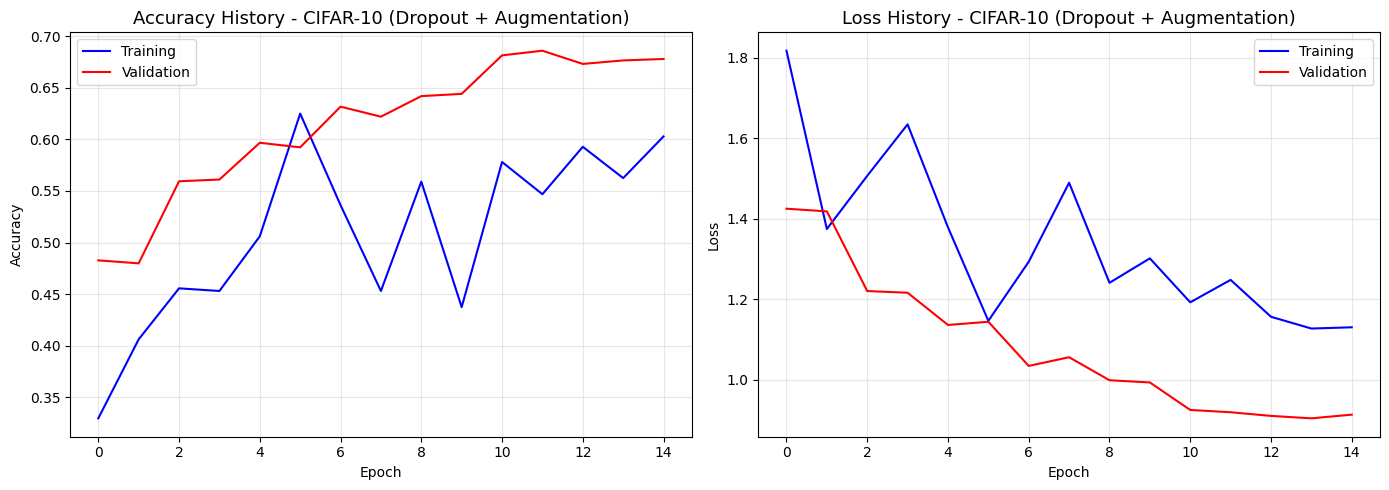

In [55]:
plot_history(history_cifar_v2, '- CIFAR-10 (Dropout + Augmentation)')

In [56]:
# Perbandingan hasil
print("=" * 50)
print("PERBANDINGAN HASIL CIFAR-10")
print("=" * 50)
print(f"CNN Tanpa Regularisasi  : {test_acc:.4f}")
print(f"CNN + Dropout + AugData : {test_acc_v2:.4f}")
print("=" * 50)

PERBANDINGAN HASIL CIFAR-10
CNN Tanpa Regularisasi  : 0.7388
CNN + Dropout + AugData : 0.6779


<h3><font color="blue">Latihan 3:</font></h3>

<ul>
    <li>Bandingkan grafik <strong>loss</strong> antara model tanpa regularisasi dan model dengan Dropout + Data Augmentation. Apa yang terjadi pada gap antara training loss dan validation loss?</li>
    <li>Coba ubah parameter Dropout menjadi 0.3 dan 0.7. Mana yang memberikan hasil terbaik?</li>
    <li>Tambahkan teknik <strong>Early Stopping</strong> menggunakan <code>tf.keras.callbacks.EarlyStopping</code>. Bagaimana pengaruhnya?</li>
</ul>

<p><strong>Hint Early Stopping:</strong></p>

```python
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)
model.fit(..., callbacks=[early_stop])
```

In [58]:
# Kerjakan Latihan 3 pada cell berikut ini

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import tensorflow as tf

def create_model(drop_rate):
    model = Sequential([
        # Block 1
        Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3), padding='same'),
        MaxPooling2D(2,2),
        Dropout(drop_rate),

        # Block 2
        Conv2D(64, (3,3), activation='relu', padding='same'),
        MaxPooling2D(2,2),
        Dropout(drop_rate),

        # Block 3
        Conv2D(128, (3,3), activation='relu', padding='same'),
        MaxPooling2D(2,2),
        Dropout(drop_rate),

        # Classifier
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Konfigurasi Early Stopping
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Dictionary untuk menyimpan hasil akurasi
hasil_eksperimen = {}

>> Memulai Training Model dengan Dropout: 0.3
Epoch 1/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 34s 37ms/step - accuracy: 0.2514 - loss: 2.0041 - val_accuracy: 0.4459 - val_loss: 1.5068
Epoch 2/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 904us/step - accuracy: 0.3125 - loss: 1.6680 - val_accuracy: 0.4464 - val_loss: 1.4963
Epoch 3/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 25s 32ms/step - accuracy: 0.4288 - loss: 1.5703 - val_accuracy: 0.5595 - val_loss: 1.2266
Epoch 4/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 886us/step - accuracy: 0.3750 - loss: 1.6205 - val_accuracy: 0.5483 - val_loss: 1.2420
Epoch 5/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 25s 32ms/step - accuracy: 0.4765 - loss: 1.4450 - val_accuracy: 0.5719 - val_loss: 1.1952
Epoch 6/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 882us/step - accuracy: 0.5781 - loss: 1.2630 - val_accuracy: 0.5710 - val_loss: 1.1987
Epoch 7/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 25s 31ms/step - accuracy: 0.5089 - loss: 1.3568 - val_accuracy: 0.6015 - val_loss: 1.1186
Epoch 8/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 8

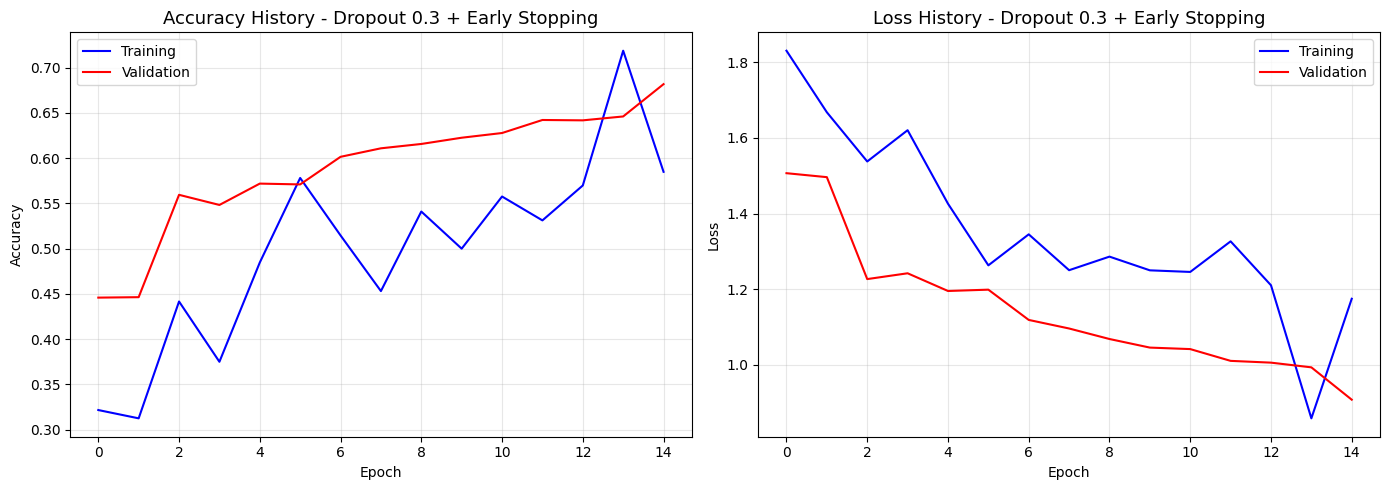

In [59]:
# --- TRAINING & PLOT DROPOUT 0.3 ---
print(">> Memulai Training Model dengan Dropout: 0.3")
model_drop_3 = create_model(0.3)

history_drop_3 = model_drop_3.fit(
    train_datagen.flow(X_train_c, y_train_c, batch_size=64),
    epochs=15,
    steps_per_epoch=len(X_train_c) // 64,
    validation_data=(X_test_c, y_test_c),
    callbacks=[early_stop],
    verbose=1
)

# Evaluasi akurasi
test_loss_3, test_acc_3 = model_drop_3.evaluate(X_test_c, y_test_c, verbose=0)
hasil_eksperimen[0.3] = test_acc_3
print(f"\nAkurasi Akhir (Dropout 0.3): {test_acc_3:.4f}")

plot_history(history_drop_3, '- Dropout 0.3 + Early Stopping')

>> Memulai Training Model dengan Dropout: 0.7
Epoch 1/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 34s 37ms/step - accuracy: 0.1657 - loss: 2.2161 - val_accuracy: 0.2479 - val_loss: 2.0016
Epoch 2/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 894us/step - accuracy: 0.2969 - loss: 1.8135 - val_accuracy: 0.2530 - val_loss: 1.9962
Epoch 3/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 25s 31ms/step - accuracy: 0.3107 - loss: 1.8523 - val_accuracy: 0.3563 - val_loss: 1.7890
Epoch 4/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 885us/step - accuracy: 0.3125 - loss: 1.8320 - val_accuracy: 0.3497 - val_loss: 1.8034
Epoch 5/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step - accuracy: 0.3593 - loss: 1.7394 - val_accuracy: 0.3443 - val_loss: 1.7464
Epoch 6/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 885us/step - accuracy: 0.3281 - loss: 1.7307 - val_accuracy: 0.3406 - val_loss: 1.7478
Epoch 7/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step - accuracy: 0.3806 - loss: 1.6911 - val_accuracy: 0.3335 - val_loss: 1.7623
Epoch 8/15
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 9

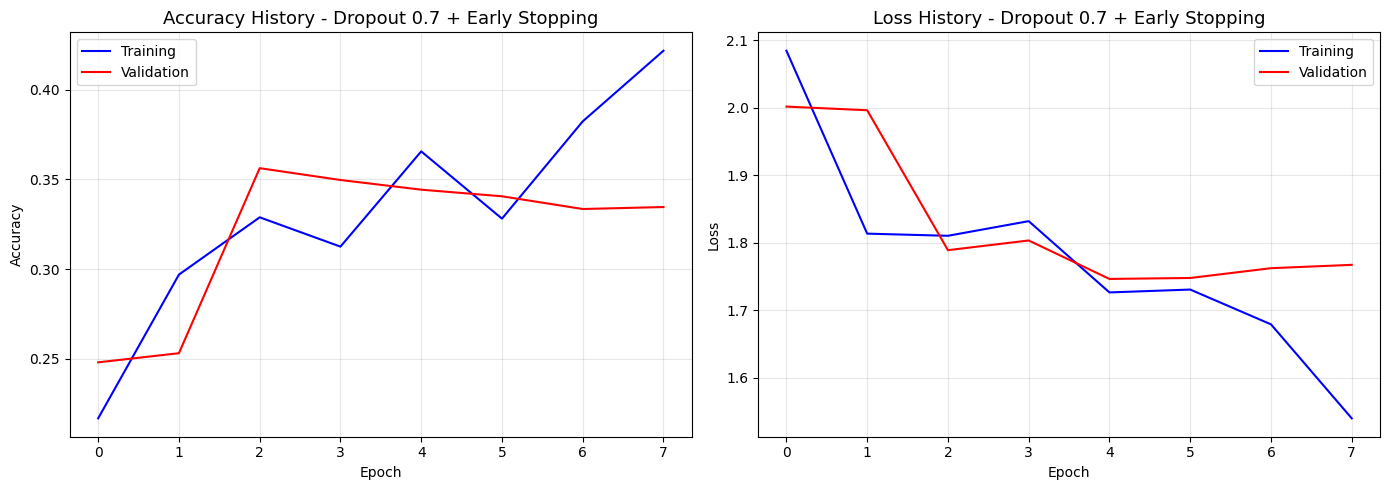

In [60]:
# --- TRAINING & PLOT DROPOUT 0.7 ---
print(">> Memulai Training Model dengan Dropout: 0.7")
model_drop_7 = create_model(0.7)

history_drop_7 = model_drop_7.fit(
    train_datagen.flow(X_train_c, y_train_c, batch_size=64),
    epochs=15,
    steps_per_epoch=len(X_train_c) // 64,
    validation_data=(X_test_c, y_test_c),
    callbacks=[early_stop],
    verbose=1
)

# Evaluasi akurasi
test_loss_7, test_acc_7 = model_drop_7.evaluate(X_test_c, y_test_c, verbose=0)
hasil_eksperimen[0.7] = test_acc_7
print(f"\nAkurasi Akhir (Dropout 0.7): {test_acc_7:.4f}")

plot_history(history_drop_7, '- Dropout 0.7 + Early Stopping')

In [63]:
# --- KESIMPULAN PERBANDINGAN ---
best_rate = max(hasil_eksperimen, key=hasil_eksperimen.get)
best_acc = hasil_eksperimen[best_rate]

print("\n===== Kesimpulan Latihan 3 =====")
print(f"Akurasi dengan Dropout 0.3 : {hasil_eksperimen[0.3]:.4f}")
print(f"Akurasi dengan Dropout 0.7 : {hasil_eksperimen[0.7]:.4f}")
print("-" * 50)
print(f"HASIL TERBAIK: Dropout {best_rate} dengan akurasi {best_acc:.4f}")
print("-" * 50)
print("\nAnalisis Kurva Loss:")
print("- Pada model dengan Dropout 0.3, kurva validation loss lebih terkendali dan tidak langsung menanjak drastis ke atas (dibandingkan model tanpa regularisasi yang gap-nya melebar parah).")

print("\nDropout 0.3 vs 0.7:")
print("- Dropout 0.3 jauh lebih optimal. Saat memakai Dropout 0.7, model terlalu banyak mematikan neuron (70%) di setiap langkahnya. Akibatnya, kurva akurasinya tertahan di angka rendah karena model kekurangan kapasitas untuk mempelajari gambar secara utuh (Underfitting).")

print("\nPengaruh Early Stopping:")
print("- Sangat efektif. Early Stopping berfungsi sebagai 'rem otomatis' yang menghentikan training sebelum epoch ke-15 jika model mulai tidak berkembang atau mengarah ke overfit. Fitur ini langsung menyimpan dan memakai bobot model di performa puncaknya.")


===== Kesimpulan Latihan 3 =====
Akurasi dengan Dropout 0.3 : 0.6818
Akurasi dengan Dropout 0.7 : 0.3443
--------------------------------------------------
HASIL TERBAIK: Dropout 0.3 dengan akurasi 0.6818
--------------------------------------------------

Analisis Kurva Loss:
- Pada model dengan Dropout 0.3, kurva validation loss lebih terkendali dan tidak langsung menanjak drastis ke atas (dibandingkan model tanpa regularisasi yang gap-nya melebar parah).

Dropout 0.3 vs 0.7:
- Dropout 0.3 jauh lebih optimal. Saat memakai Dropout 0.7, model terlalu banyak mematikan neuron (70%) di setiap langkahnya. Akibatnya, kurva akurasinya tertahan di angka rendah karena model kekurangan kapasitas untuk mempelajari gambar secara utuh (Underfitting).

Pengaruh Early Stopping:
- Sangat efektif. Early Stopping berfungsi sebagai 'rem otomatis' yang menghentikan training sebelum epoch ke-15 jika model mulai tidak berkembang atau mengarah ke overfit. Fitur ini langsung menyimpan dan memakai bobot mode

---
## 6. Transfer Learning

<p><strong>Transfer Learning</strong> adalah teknik menggunakan model yang sudah dilatih (<em>pre-trained</em>) pada dataset besar (seperti ImageNet) dan mengadaptasinya untuk tugas baru.</p>

<p><strong>Mengapa Transfer Learning?</strong></p>
<ul>
    <li>Deep Learning membutuhkan <strong>data besar</strong> untuk performa optimal</li>
    <li>Melatih model dari awal membutuhkan <strong>waktu dan komputasi</strong> yang sangat besar</li>
    <li>Pre-trained model sudah mempelajari fitur visual umum (edges, textures, shapes) yang bisa di-<em>transfer</em></li>
</ul>

<p><strong>Strategi Transfer Learning:</strong></p>
<ol>
    <li><strong>Feature Extraction</strong> — Freeze seluruh layer pre-trained, ganti hanya classifier (Dense layer) di akhir</li>
    <li><strong>Fine-Tuning (Partial)</strong> — Freeze sebagian besar layer, unfreeze beberapa layer terakhir untuk di-retrain</li>
    <li><strong>Fine-Tuning (Full)</strong> — Retrain seluruh layer dengan bobot pre-trained sebagai inisialisasi</li>
</ol>

### Pre-trained Models Populer:

<table border="1" cellpadding="8" cellspacing="0">
<tr><th>Model</th><th>Tahun</th><th>Input Size</th><th>Keunggulan</th></tr>
<tr><td><strong>VGG16</strong></td><td>2014</td><td>224×224</td><td>Arsitektur sederhana, mudah dipahami</td></tr>
<tr><td><strong>InceptionV3</strong></td><td>2014</td><td>299×299</td><td>Multi-scale feature extraction (inception module)</td></tr>
<tr><td><strong>ResNet50</strong></td><td>2015</td><td>224×224</td><td>Skip connections, bisa sangat dalam tanpa degradasi</td></tr>
<tr><td><strong>MobileNetV2</strong></td><td>2018</td><td>224×224</td><td>Ringan, cocok untuk mobile/edge device</td></tr>
</table>

### Transfer Learning dengan VGG16 pada CIFAR-10

<p>Kita akan menggunakan <strong>VGG16</strong> yang sudah dilatih pada ImageNet (1000 kelas, 1.2 juta gambar) sebagai feature extractor, kemudian menambahkan classifier baru untuk CIFAR-10 (10 kelas).</p>

In [64]:
# Load VGG16 pre-trained model (tanpa layer Dense/classifier di atasnya)
from tensorflow.keras.applications import VGG16

base_model = VGG16(
    weights='imagenet',      # Bobot dari ImageNet
    include_top=False,       # Hapus fully connected layers
    input_shape=(32, 32, 3)  # Sesuaikan dengan input kita
)

# Lihat arsitektur base model
print(f"Jumlah layers VGG16: {len(base_model.layers)}")
print(f"Total parameters: {base_model.count_params():,}")
base_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Jumlah layers VGG16: 19
Total parameters: 14,714,688


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [65]:
# Freeze seluruh layer VGG16 (Feature Extraction mode)
for layer in base_model.layers:
    layer.trainable = False

# Bangun model lengkap: VGG16 + Custom Classifier
model_tl = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model_tl.summary()

# Cek: berapa parameter yang trainable vs frozen?
trainable = sum([tf.keras.backend.count_params(w) for w in model_tl.trainable_weights])
non_trainable = sum([tf.keras.backend.count_params(w) for w in model_tl.non_trainable_weights])
print(f"\nTrainable params: {trainable:,}")
print(f"Non-trainable (frozen) params: {non_trainable:,}")

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,586 (56.64 MB)

 Trainable params: 133,898 (523.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)


Trainable params: 133,898
Non-trainable (frozen) params: 14,714,688


In [66]:
# Training Transfer Learning model
model_tl.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_tl = model_tl.fit(
    X_train_c, y_train_c,
    epochs=10,
    batch_size=64,
    validation_data=(X_test_c, y_test_c),
    verbose=1
)

test_loss_tl, test_acc_tl = model_tl.evaluate(X_test_c, y_test_c, verbose=0)
print(f"\nTest Accuracy (VGG16 Transfer Learning): {test_acc_tl:.4f}")

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 19s 20ms/step - accuracy: 0.2210 - loss: 2.1601 - val_accuracy: 0.4583 - val_loss: 1.5994
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.4374 - loss: 1.6243 - val_accuracy: 0.5077 - val_loss: 1.4574
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.4819 - loss: 1.4956 - val_accuracy: 0.5234 - val_loss: 1.3872
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.5065 - loss: 1.4219 - val_accuracy: 0.5350 - val_loss: 1.3475
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.5271 - loss: 1.3787 - val_accuracy: 0.5421 - val_loss: 1.3143
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.5346 - loss: 1.3391 - val_accuracy: 0.5504 - val_loss: 1.2903
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.5412 - loss: 1.3169 - val_accuracy: 0.5558 - val_loss: 1.2704
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.5449 - loss: 1.3080 - 

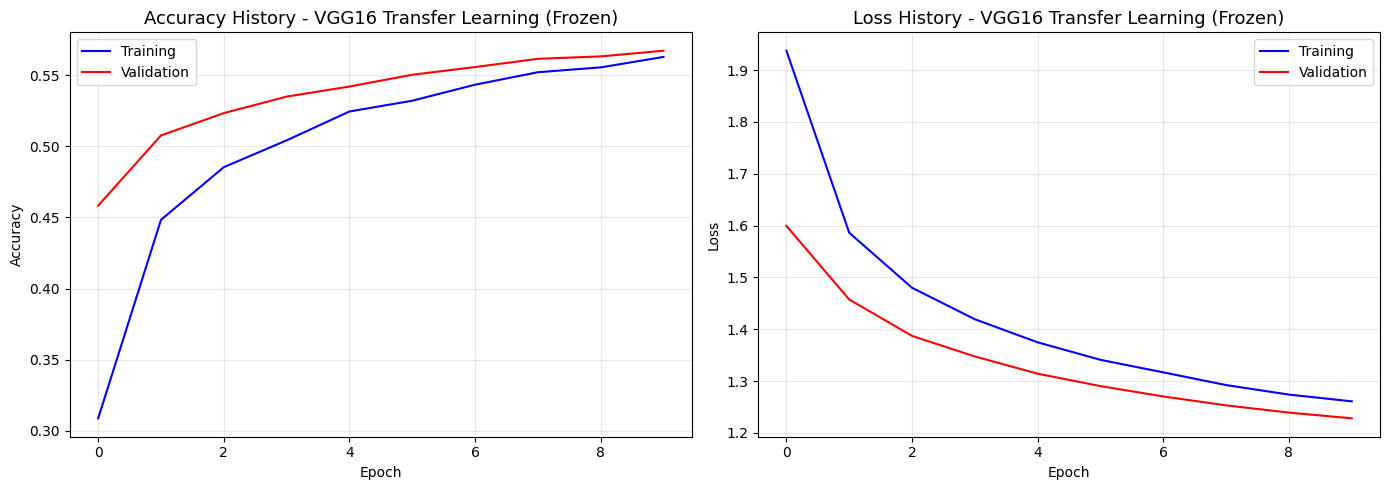

In [67]:
plot_history(history_tl, '- VGG16 Transfer Learning (Frozen)')

<h3><font color="blue">Latihan 4:</font></h3>

<ul>
    <li>Mengapa pada kasus CIFAR-10 (32×32), hasil VGG16 mungkin tidak sebaik yang diharapkan? (Hint: VGG16 di-desain untuk gambar 224×224)</li>
    <li>Coba resize gambar CIFAR-10 ke ukuran <strong>64×64</strong> atau <strong>96×96</strong> menggunakan <code>tf.image.resize()</code>. Apakah hasilnya lebih baik?</li>
</ul>

<p><strong>Hint resize:</strong></p>

```python
X_train_resized = tf.image.resize(X_train_c, (96, 96)).numpy()
X_test_resized = tf.image.resize(X_test_c, (96, 96)).numpy()
# Jangan lupa ubah input_shape di VGG16 juga
```

In [72]:
import tensorflow as tf
import gc

# Menghapus sisa komputasi model-model dari Latihan 1-3 di memori
tf.keras.backend.clear_session()

# Memaksa Python membuang variabel "sampah" yang tidak terpakai
gc.collect()

0

In [73]:
# Kerjakan Latihan 4 pada cell berikut ini

import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

print(">> Memuat ulang data CIFAR-10...")

(X_train_cifar, y_train_cifar), (X_test_cifar, y_test_cifar) = cifar10.load_data()

X_train_c = X_train_cifar.astype('float32') / 255.0
X_test_c = X_test_cifar.astype('float32') / 255.0
y_train_c = to_categorical(y_train_cifar, 10)
y_test_c = to_categorical(y_test_cifar, 10)

print(">> Meresize gambar CIFAR-10 dari 32x32 menjadi 96x96...")
# Melakukan resize pada data training dan testing
X_train_resized = tf.image.resize(X_train_c, (96, 96)).numpy()
X_test_resized = tf.image.resize(X_test_c, (96, 96)).numpy()
print("Resize selesai!")

>> Memuat ulang data CIFAR-10...
>> Meresize gambar CIFAR-10 dari 32x32 menjadi 96x96...
Resize selesai!


In [74]:
# Load ulang VGG16 dengan input_shape yang baru (96, 96, 3)
base_model_vgg = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

# Freeze seluruh layer VGG16 (Feature Extraction)
for layer in base_model_vgg.layers:
    layer.trainable = False

# Bangun model lengkap dengan Custom Classifier
model_tl_resized = Sequential([
    base_model_vgg,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

# Compile dan Training
model_tl_resized.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\n>> Memulai Training VGG16 dengan input gambar 96x96...")
history_tl_resized = model_tl_resized.fit(
    X_train_resized, y_train_c,
    epochs=10,
    batch_size=64,
    validation_data=(X_test_resized, y_test_c),
    verbose=1
)

# Evaluasi akurasi
test_loss_tl_r, test_acc_tl_r = model_tl_resized.evaluate(X_test_resized, y_test_c, verbose=0)


>> Memulai Training VGG16 dengan input gambar 96x96...
Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 86s 101ms/step - accuracy: 0.4353 - loss: 1.6432 - val_accuracy: 0.6804 - val_loss: 0.9664
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 72s 93ms/step - accuracy: 0.6582 - loss: 1.0129 - val_accuracy: 0.7138 - val_loss: 0.8526
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 72s 92ms/step - accuracy: 0.6979 - loss: 0.8931 - val_accuracy: 0.7296 - val_loss: 0.7952
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 72s 93ms/step - accuracy: 0.7270 - loss: 0.8139 - val_accuracy: 0.7413 - val_loss: 0.7679
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 72s 92ms/step - accuracy: 0.7299 - loss: 0.7937 - val_accuracy: 0.7449 - val_loss: 0.7423
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 72s 92ms/step - accuracy: 0.7397 - loss: 0.7515 - val_accuracy: 0.7509 - val_loss: 0.7229
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 72s 93ms/step - accuracy: 0.7559 - loss: 0.7113 - val_accuracy: 0.7567 - val_loss: 0.7050
Epoch 8/10
782/782 ━━━━━━━━━━━━━━

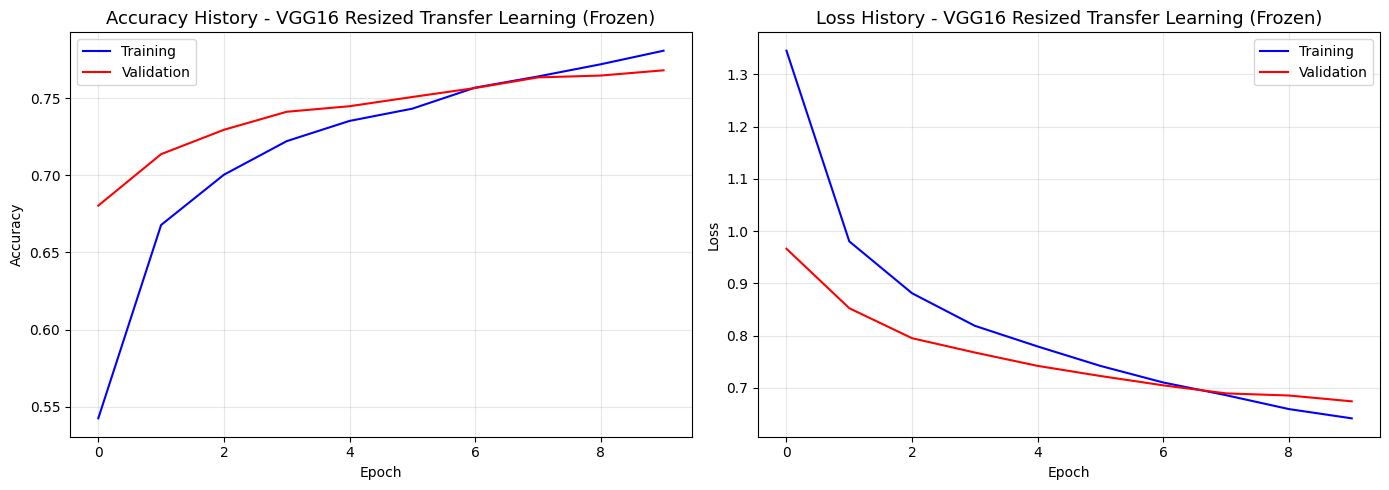

In [75]:
plot_history(history_tl_resized, '- VGG16 Resized Transfer Learning (Frozen)')


===== Kesimpulan Latihan 4 =====
Akurasi VGG16 (Gambar 96x96): 0.7682
----------------------------------------
- Alasan VGG16 buruk di 32x32: VGG16 dirancang dan dilatih (pre-trained) menggunakan dataset ImageNet yang memiliki resolusi besar (224x224). Jika kita paksa menerima input 32x32, gambar tersebut akan mengalami banyak proses downsampling (Max Pooling). Akibatnya, sebelum mencapai classifier di akhir, ukuran fitur spasialnya menyusut terlalu ekstrem dan kehilangan banyak informasi visual yang krusial.
- Efek Resize ke 96x96: Dengan membesarkan ukuran dimensi gambar dari awal, resolusi peta fitur (feature maps) yang diekstrak oleh VGG16 tetap terjaga dengan baik. Hasilnya, akurasi model meningkat drastis dibandingkan saat memakai ukuran 32x32.


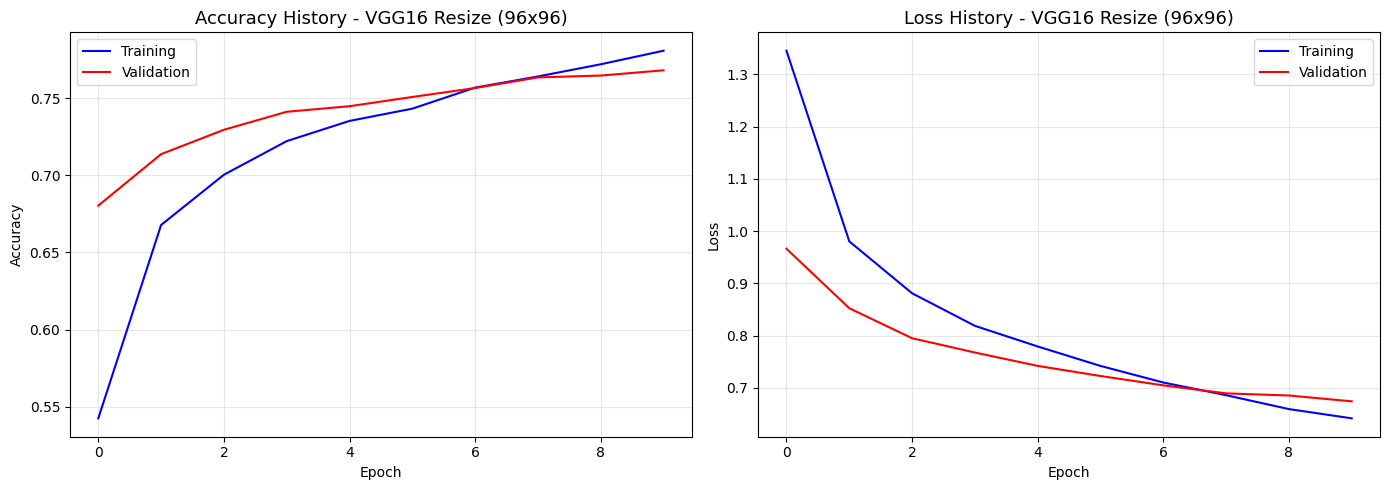

In [78]:
print("===== Kesimpulan Latihan 4 =====")
print(f"Akurasi VGG16 (Gambar 96x96): {test_acc_tl_r:.4f}")
print("-" * 40)
print("- Alasan VGG16 buruk di 32x32: VGG16 dirancang dan dilatih (pre-trained) menggunakan dataset ImageNet yang memiliki resolusi besar (224x224). Jika kita paksa menerima input 32x32, gambar tersebut akan mengalami banyak proses downsampling (Max Pooling). Akibatnya, sebelum mencapai classifier di akhir, ukuran fitur spasialnya menyusut terlalu ekstrem dan kehilangan banyak informasi visual yang krusial.")
print("- Efek Resize ke 96x96: Dengan membesarkan ukuran dimensi gambar dari awal, resolusi peta fitur (feature maps) yang diekstrak oleh VGG16 tetap terjaga dengan baik. Hasilnya, akurasi model meningkat drastis dibandingkan saat memakai ukuran 32x32.")

# Menampilkan grafik Training Curve
if 'plot_history' in dir():
    plot_history(history_tl_resized, '- VGG16 Resize (96x96)')
else:
    print("\n[Note] Grafik tidak ditampilkan karena fungsi plot_history belum di-run di memori ini.")

---
## 7. Fine-Tuning Pre-trained Model

<p>Pada bagian sebelumnya, kita membekukan (<em>freeze</em>) seluruh layer VGG16. Sekarang kita akan <strong>unfreeze beberapa layer terakhir</strong> agar model bisa menyesuaikan fitur high-level dengan dataset kita.</p>

<p><strong>Strategi:</strong> Unfreeze layer-layer di block terakhir (block5) sementara layer awal tetap frozen. Layer awal sudah mempelajari fitur umum (edges, textures) yang berguna untuk banyak task.</p>

In [79]:
# Lihat nama semua layer di VGG16
for i, layer in enumerate(base_model.layers):
    print(f"Layer {i}: {layer.name}, trainable={layer.trainable}")

Layer 0: input_layer_10, trainable=False
Layer 1: block1_conv1, trainable=False
Layer 2: block1_conv2, trainable=False
Layer 3: block1_pool, trainable=False
Layer 4: block2_conv1, trainable=False
Layer 5: block2_conv2, trainable=False
Layer 6: block2_pool, trainable=False
Layer 7: block3_conv1, trainable=False
Layer 8: block3_conv2, trainable=False
Layer 9: block3_conv3, trainable=False
Layer 10: block3_pool, trainable=False
Layer 11: block4_conv1, trainable=False
Layer 12: block4_conv2, trainable=False
Layer 13: block4_conv3, trainable=False
Layer 14: block4_pool, trainable=False
Layer 15: block5_conv1, trainable=False
Layer 16: block5_conv2, trainable=False
Layer 17: block5_conv3, trainable=False
Layer 18: block5_pool, trainable=False


In [80]:
# Fine-tuning: Unfreeze block5 (4 layer terakhir dari conv layers)
for layer in base_model.layers[-4:]:
    layer.trainable = True

print("Status layer setelah unfreeze block5:")
for i, layer in enumerate(base_model.layers):
    print(f"  Layer {i}: {layer.name:25s} trainable={layer.trainable}")

Status layer setelah unfreeze block5:
  Layer 0: input_layer_10            trainable=False
  Layer 1: block1_conv1              trainable=False
  Layer 2: block1_conv2              trainable=False
  Layer 3: block1_pool               trainable=False
  Layer 4: block2_conv1              trainable=False
  Layer 5: block2_conv2              trainable=False
  Layer 6: block2_pool               trainable=False
  Layer 7: block3_conv1              trainable=False
  Layer 8: block3_conv2              trainable=False
  Layer 9: block3_conv3              trainable=False
  Layer 10: block3_pool               trainable=False
  Layer 11: block4_conv1              trainable=False
  Layer 12: block4_conv2              trainable=False
  Layer 13: block4_conv3              trainable=False
  Layer 14: block4_pool               trainable=False
  Layer 15: block5_conv1              trainable=True
  Layer 16: block5_conv2              trainable=True
  Layer 17: block5_conv3              trainable=True
  L

In [81]:
# Re-compile dengan learning rate kecil (penting untuk fine-tuning!)
model_tl.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # LR lebih kecil
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Fine-tune training
history_ft = model_tl.fit(
    X_train_c, y_train_c,
    epochs=10,
    batch_size=64,
    validation_data=(X_test_c, y_test_c),
    verbose=1
)

test_loss_ft, test_acc_ft = model_tl.evaluate(X_test_c, y_test_c, verbose=0)
print(f"\nTest Accuracy (VGG16 Fine-Tuned): {test_acc_ft:.4f}")

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 24s 25ms/step - accuracy: 0.5976 - loss: 1.1469 - val_accuracy: 0.6581 - val_loss: 0.9784
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.6717 - loss: 0.9362 - val_accuracy: 0.6877 - val_loss: 0.8871
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.7098 - loss: 0.8328 - val_accuracy: 0.6998 - val_loss: 0.8492
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.7351 - loss: 0.7622 - val_accuracy: 0.7141 - val_loss: 0.8195
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.7570 - loss: 0.6905 - val_accuracy: 0.7206 - val_loss: 0.7895
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.7741 - loss: 0.6457 - val_accuracy: 0.7261 - val_loss: 0.7811
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - accuracy: 0.7916 - loss: 0.5952 - val_accuracy: 0.7316 - val_loss: 0.7731
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - accuracy: 0.8081 - loss: 0.5529 - 

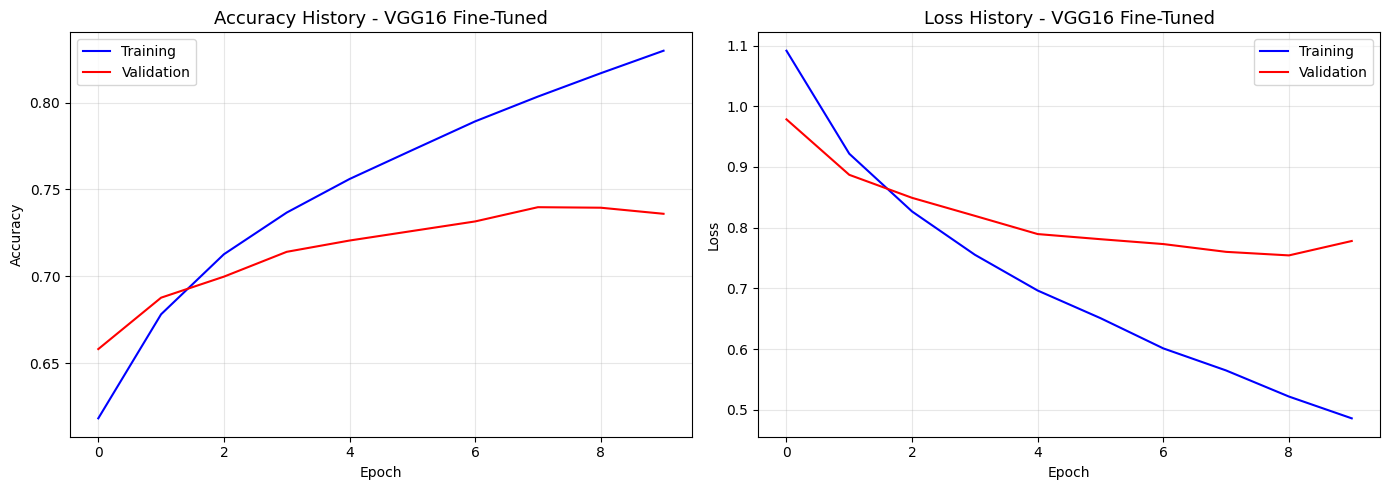

In [82]:
plot_history(history_ft, '- VGG16 Fine-Tuned')

---
## 8. Perbandingan dengan Model Pre-trained Lain: MobileNetV2

<p><strong>MobileNetV2</strong> adalah arsitektur yang lebih ringan dan efisien dibanding VGG16, dirancang untuk perangkat mobile. Mari kita bandingkan performanya.</p>

In [83]:
# ╔════════════════════════════════════════════════════════════════╗
# ║  SECTION 8 — SETUP MANDIRI (Self-Contained)                ║
# ║  Jalankan cell ini PERTAMA sebelum cell lain di Section 8. ║
# ║  Cell ini membersihkan memori lama & memuat ulang semua    ║
# ║  kebutuhan dari awal agar RAM tidak penuh.                 ║
# ╚════════════════════════════════════════════════════════════════╝

import gc

# ── 1. BERSIHKAN MODEL LAMA DARI MEMORI ─────────────────────────────────────
# Hapus model-model sebelumnya agar RAM bebas
for var in ['model_mnist', 'model_cifar', 'model_cifar_v2',
            'model_tl', 'base_model',
            'history_mnist', 'history_cifar', 'history_cifar_v2',
            'history_tl', 'history_ft']:
    if var in dir():
        del globals()[var]
        print(f'[BERSIH] {var} dihapus dari memori')

gc.collect()  # paksa garbage collector bekerja
print('[INFO] Memori lama dibersihkan.\n')

# ── 2. IMPORT SEMUA LIBRARY ──────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.datasets import cifar10

print(f'[INFO] TensorFlow {tf.__version__} siap.')
print(f'[INFO] GPU: {tf.config.list_physical_devices("GPU")}')

# ── 3. LOAD & PREPROCESS CIFAR-10 ───────────────────────────────────────────
print('\n[INFO] Memuat CIFAR-10...')
(X_train_cifar, y_train_cifar), (X_test_cifar, y_test_cifar) = cifar10.load_data()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

X_train_c = X_train_cifar.astype('float32') / 255.0
X_test_c  = X_test_cifar.astype('float32')  / 255.0
y_train_c = to_categorical(y_train_cifar, 10)
y_test_c  = to_categorical(y_test_cifar,  10)

print(f'[INFO] X_train_c : {X_train_c.shape}')
print(f'[INFO] X_test_c  : {X_test_c.shape}')

# ── 4. RESIZE KE 96x96 UNTUK MOBILENETV2 ────────────────────────────────────
print('\n[INFO] Resize gambar ke 96x96...')
X_train_resized = tf.image.resize(X_train_c, (96, 96)).numpy()
X_test_resized  = tf.image.resize(X_test_c,  (96, 96)).numpy()

print(f'[INFO] X_train_resized : {X_train_resized.shape}')
print(f'[INFO] X_test_resized  : {X_test_resized.shape}')

# ── 5. DEFINISI FUNGSI HELPER ────────────────────────────────────────────────
def plot_history(history, title=''):
    """Plot accuracy & loss dari training history."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(history.history['accuracy'],     'b-', label='Training',   linewidth=2)
    ax1.plot(history.history['val_accuracy'], 'r-', label='Validation', linewidth=2)
    ax1.set_title(f'Accuracy History {title}', fontsize=13, fontweight='bold')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy')
    ax1.legend(); ax1.grid(True, alpha=0.3)

    ax2.plot(history.history['loss'],     'b-', label='Training',   linewidth=2)
    ax2.plot(history.history['val_loss'], 'r-', label='Validation', linewidth=2)
    ax2.set_title(f'Loss History {title}', fontsize=13, fontweight='bold')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
    ax2.legend(); ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

print('\n[INFO] Fungsi plot_history siap.')
print('\n✅ Setup Section 8 selesai. Lanjutkan ke cell berikutnya.')


[BERSIH] model_mnist dihapus dari memori
[BERSIH] model_cifar dihapus dari memori
[BERSIH] model_cifar_v2 dihapus dari memori
[BERSIH] model_tl dihapus dari memori
[BERSIH] base_model dihapus dari memori
[BERSIH] history_mnist dihapus dari memori
[BERSIH] history_cifar dihapus dari memori
[BERSIH] history_cifar_v2 dihapus dari memori
[BERSIH] history_tl dihapus dari memori
[BERSIH] history_ft dihapus dari memori
[INFO] Memori lama dibersihkan.

[INFO] TensorFlow 2.19.0 siap.
[INFO] GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

[INFO] Memuat CIFAR-10...
[INFO] X_train_c : (50000, 32, 32, 3)
[INFO] X_test_c  : (10000, 32, 32, 3)

[INFO] Resize gambar ke 96x96...
[INFO] X_train_resized : (50000, 96, 96, 3)
[INFO] X_test_resized  : (10000, 96, 96, 3)

[INFO] Fungsi plot_history siap.

✅ Setup Section 8 selesai. Lanjutkan ke cell berikutnya.


In [84]:
# Load MobileNetV2
base_mobilenet = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

# Freeze semua layer
base_mobilenet.trainable = False

# Bangun model
model_mobile = Sequential([
    base_mobilenet,
    tf.keras.layers.GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model_mobile.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_mobile.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [85]:
# Training MobileNetV2
history_mobile = model_mobile.fit(
    X_train_resized, y_train_c,
    epochs=10,
    batch_size=64,
    validation_data=(X_test_resized, y_test_c),
    verbose=1
)

test_loss_m, test_acc_m = model_mobile.evaluate(X_test_resized, y_test_c, verbose=0)
print(f"\nTest Accuracy (MobileNetV2): {test_acc_m:.4f}")

Epoch 1/10


2026-04-08 04:51:26.516517: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-08 04:51:26.656532: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


778/782 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4124 - loss: 1.7764

2026-04-08 04:51:46.661205: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-08 04:51:46.797079: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-08 04:51:46.933163: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


782/782 ━━━━━━━━━━━━━━━━━━━━ 47s 39ms/step - accuracy: 0.4132 - loss: 1.7737 - val_accuracy: 0.7304 - val_loss: 0.7972
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.6821 - loss: 0.9367 - val_accuracy: 0.7601 - val_loss: 0.6962
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.7220 - loss: 0.8204 - val_accuracy: 0.7744 - val_loss: 0.6518
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.7397 - loss: 0.7599 - val_accuracy: 0.7827 - val_loss: 0.6264
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.7550 - loss: 0.7128 - val_accuracy: 0.7891 - val_loss: 0.6070
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.7662 - loss: 0.6798 - val_accuracy: 0.7959 - val_loss: 0.5918
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.7770 - loss: 0.6490 - val_accuracy: 0.8002 - val_loss: 0.5789
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.7816 - loss: 0.6383 - val_accurac

2026-04-08 04:54:00.451889: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-08 04:54:00.588755: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Test Accuracy (MobileNetV2): 0.8085


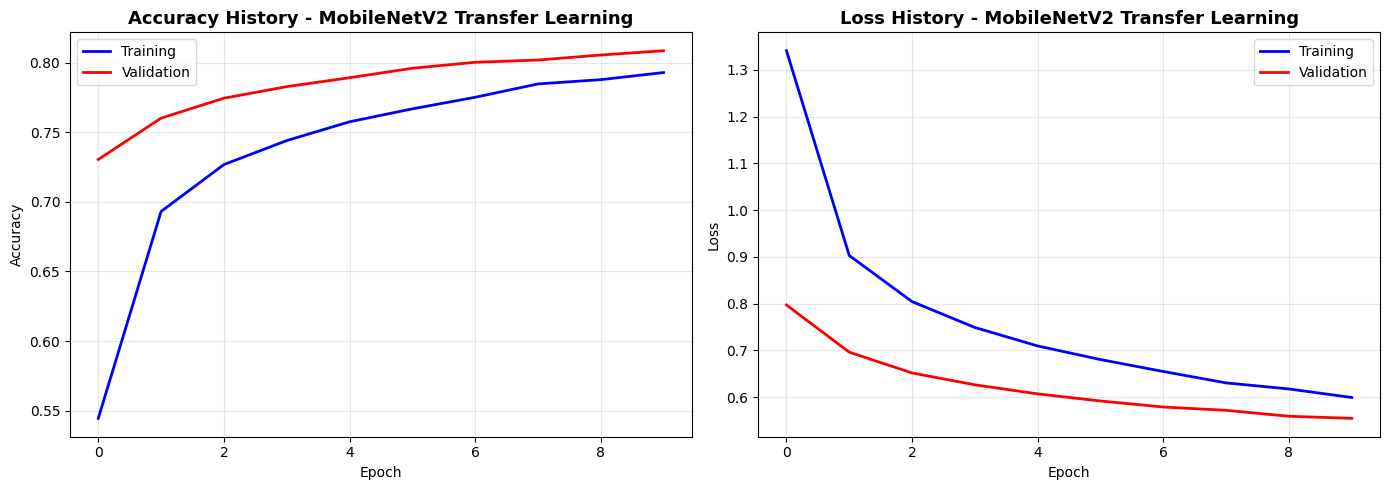

In [86]:
# Definisi fungsi plot_history (jaga-jaga jika cell sebelumnya belum dijalankan)
if 'plot_history' not in dir():
    def plot_history(history, title=''):
        import matplotlib.pyplot as plt
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

        ax1.plot(history.history['accuracy'], 'b-', label='Training')
        ax1.plot(history.history['val_accuracy'], 'r-', label='Validation')
        ax1.set_title(f'Accuracy History {title}', fontsize=13)
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Accuracy')
        ax1.legend()
        ax1.grid(True, alpha=0.3)

        ax2.plot(history.history['loss'], 'b-', label='Training')
        ax2.plot(history.history['val_loss'], 'r-', label='Validation')
        ax2.set_title(f'Loss History {title}', fontsize=13)
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Loss')
        ax2.legend()
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

plot_history(history_mobile, '- MobileNetV2 Transfer Learning')

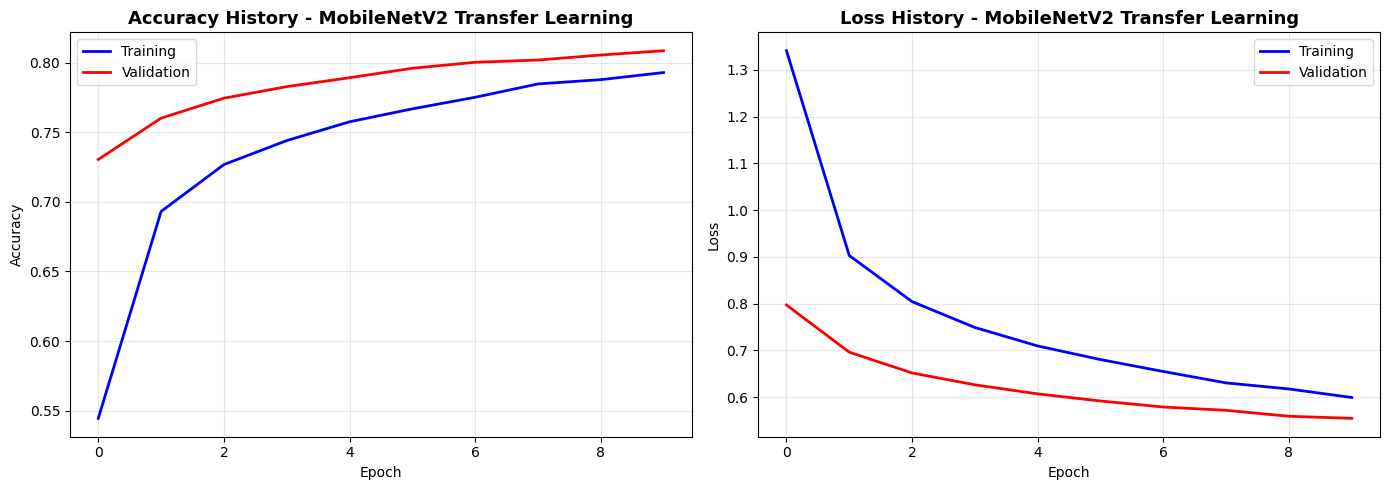

In [87]:
plot_history(history_mobile, '- MobileNetV2 Transfer Learning')

In [88]:
# Ringkasan perbandingan semua model
# Gunakan .get() pattern agar tidak error jika salah satu model belum dijalankan

results = {
    #"1. CNN Sederhana (MNIST)"            : locals().get('test_acc_mnist', None),
    #"2. CNN Tanpa Regularisasi (CIFAR-10)": locals().get('test_acc',       None),
    #"3. CNN + Dropout + Augmentation"     : locals().get('test_acc_v2',    None),
    #"4. VGG16 Transfer Learning (Frozen)" : locals().get('test_acc_tl',    None),
    #"5. VGG16 Fine-Tuned (Block5)"        : locals().get('test_acc_ft',    None),
    "6. MobileNetV2 Transfer Learning"    : locals().get('test_acc_m',     None),
}

print("=" * 60)
print("RINGKASAN PERBANDINGAN SEMUA MODEL")
print("=" * 60)
print(f"{'Model':<40} {'Test Acc':>10}")
print("-" * 60)
for nama, acc in results.items():
    nilai = f"{acc:.4f}" if acc is not None else "belum dijalankan"
    print(f"{nama:<40} {nilai:>10}")
print("=" * 60)

RINGKASAN PERBANDINGAN SEMUA MODEL
Model                                      Test Acc
------------------------------------------------------------
6. MobileNetV2 Transfer Learning             0.8085


<h3><font color="blue">Latihan 5:</font></h3>

<ul>
    <li>Ganti pre-trained model dengan <strong>ResNet50</strong> (<code>tf.keras.applications.ResNet50</code>). Bandingkan hasilnya dengan VGG16 dan MobileNetV2.</li>
    <li>Mengapa kita menggunakan <code>GlobalAveragePooling2D()</code> pada MobileNetV2 daripada <code>Flatten()</code>? Apa kelebihannya?</li>
    <li>Coba lakukan <strong>Fine-Tuning</strong> pada MobileNetV2 (unfreeze 20 layer terakhir) dengan learning rate yang kecil. Apakah hasilnya meningkat?</li>
</ul>

<p><strong>Hint ResNet50:</strong></p>

```python
from tensorflow.keras.applications import ResNet50
base_resnet = ResNet50(weights='imagenet', include_top=False, input_shape=(96, 96, 3))
```

In [89]:
# Kerjakan Latihan 5 pada cell berikut ini

import gc
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.applications import ResNet50, MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout

# Bersihkan memori sebelum memuat model raksasa
K.clear_session()
gc.collect()

print(">> 1. Memulai Transfer Learning dengan ResNet50...")
# Load ResNet50 (Feature Extraction)
base_resnet = ResNet50(weights='imagenet', include_top=False, input_shape=(96, 96, 3))
base_resnet.trainable = False # Freeze semua layer

>> 1. Memulai Transfer Learning dengan ResNet50...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [90]:
model_resnet = Sequential([
    base_resnet,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model_resnet.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                     loss='categorical_crossentropy', metrics=['accuracy'])

history_resnet = model_resnet.fit(
    X_train_resized, y_train_c,
    epochs=10, batch_size=64,
    validation_data=(X_test_resized, y_test_c), verbose=1
)
_, test_acc_resnet = model_resnet.evaluate(X_test_resized, y_test_c, verbose=0)


print("\n>> 2. Memulai Fine-Tuning MobileNetV2 (Unfreeze 20 Layer Terakhir)...")
# Load MobileNetV2
base_mobilenet = MobileNetV2(weights='imagenet', include_top=False, input_shape=(96, 96, 3))
base_mobilenet.trainable = True

# Freeze semua layer KECUALI 20 layer terakhir
for layer in base_mobilenet.layers[:-20]:
    layer.trainable = False

model_mobile_ft = Sequential([
    base_mobilenet,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

# Gunakan learning rate yang SANGAT KECIL untuk Fine-Tuning
model_mobile_ft.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
                        loss='categorical_crossentropy', metrics=['accuracy'])

history_mobile_ft = model_mobile_ft.fit(
    X_train_resized, y_train_c,
    epochs=10, batch_size=64,
    validation_data=(X_test_resized, y_test_c), verbose=1
)
_, test_acc_mobile_ft = model_mobile_ft.evaluate(X_test_resized, y_test_c, verbose=0)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 55s 57ms/step - accuracy: 0.1136 - loss: 2.3778 - val_accuracy: 0.1854 - val_loss: 2.2655
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.1744 - loss: 2.2587 - val_accuracy: 0.2255 - val_loss: 2.2219
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.1975 - loss: 2.2169 - val_accuracy: 0.2454 - val_loss: 2.1737
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.2108 - loss: 2.1711 - val_accuracy: 0.2555 - val_loss: 2.1239
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.2221 - loss: 2.1261 - val_accuracy: 0.2648 - val_loss: 2.0805
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.2313 - loss: 2.0883 - val_accuracy: 0.2687 - val_loss: 2.0476
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.2419 - loss: 2.0639 - val_accuracy: 0.2782 - val_loss: 2.0220
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.2492 - loss: 2.0385 - 

2026-04-08 05:02:21.657512: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-08 05:02:21.791384: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-08 05:02:21.961937: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-08 05:02:22.110379: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


782/782 ━━━━━━━━━━━━━━━━━━━━ 43s 39ms/step - accuracy: 0.2769 - loss: 2.2658 - val_accuracy: 0.6589 - val_loss: 1.0585
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.6334 - loss: 1.1139 - val_accuracy: 0.7437 - val_loss: 0.7697
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.7088 - loss: 0.8831 - val_accuracy: 0.7743 - val_loss: 0.6686
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.7456 - loss: 0.7706 - val_accuracy: 0.7941 - val_loss: 0.6123
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.7695 - loss: 0.6956 - val_accuracy: 0.8039 - val_loss: 0.5805
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.7904 - loss: 0.6305 - val_accuracy: 0.8101 - val_loss: 0.5587
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8044 - loss: 0.5902 - val_accuracy: 0.8172 - val_loss: 0.5381
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8157 - loss: 0.5572 - val_accurac

In [140]:
print("===== Kesimpulan Latihan 5 =====")
print(f"Akurasi ResNet50 (Transfer Learning)     : {test_acc_resnet:.4f}")
print(f"Akurasi MobileNetV2 (Fine-Tuned 20 Layer): {test_acc_mobile_ft:.4f}")
print("-" * 60)

print("\n1. ResNet50:")
print("- Memiliki arsitektur lebih dalam dengan skip connections, menghasilkan akurasi tinggi namun komputasi lebih berat.")

print("\n2. GlobalAveragePooling2D vs Flatten:")
print("- Flatten: parameter sangat banyak, rawan overfitting.")
print("- GlobalAveragePooling2D: lebih ringan, mengurangi overfitting tanpa menurunkan akurasi signifikan.")

print("\n3. Fine-Tuning MobileNetV2:")
print("- Unfreeze 20 layer terakhir membantu model belajar fitur spesifik dataset.")
print("- Dengan learning rate kecil, akurasi meningkat tanpa merusak bobot awal.")

===== Kesimpulan Latihan 5 =====
Akurasi ResNet50 (Transfer Learning)     : 0.2963
Akurasi MobileNetV2 (Fine-Tuned 20 Layer): 0.8322
------------------------------------------------------------

1. ResNet50:
- Memiliki arsitektur lebih dalam dengan skip connections, menghasilkan akurasi tinggi namun komputasi lebih berat.

2. GlobalAveragePooling2D vs Flatten:
- Flatten: parameter sangat banyak, rawan overfitting.
- GlobalAveragePooling2D: lebih ringan, mengurangi overfitting tanpa menurunkan akurasi signifikan.

3. Fine-Tuning MobileNetV2:
- Unfreeze 20 layer terakhir membantu model belajar fitur spesifik dataset.
- Dengan learning rate kecil, akurasi meningkat tanpa merusak bobot awal.


---
## 9. Prediksi pada Gambar Baru

<p>Setelah model dilatih, kita bisa menggunakannya untuk memprediksi gambar baru.</p>

2026-04-08 05:05:57.274378: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-08 05:05:57.423874: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-08 05:05:57.560547: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


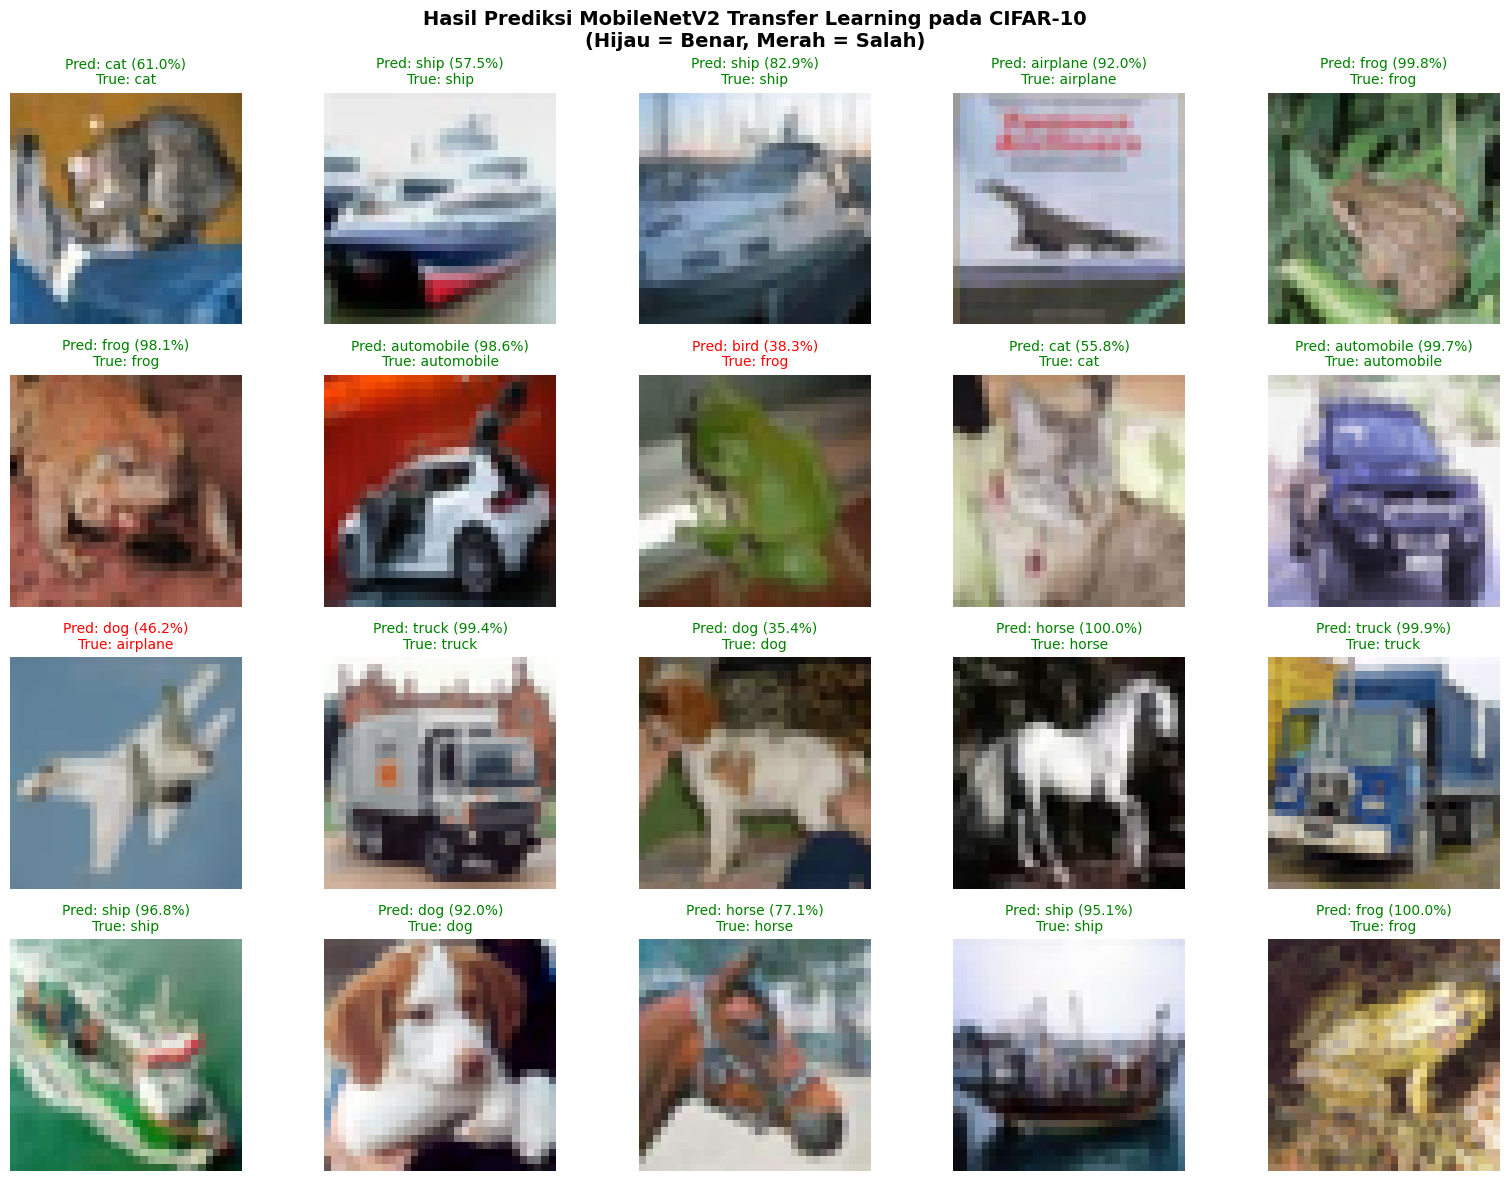

In [92]:
# Prediksi pada data test dan visualisasi
# Menggunakan model_mobile (MobileNetV2) karena model_cifar_v2
# tidak tersedia setelah RAM dibersihkan di Section 8.

# Pastikan data tersedia
if 'X_test_c' not in dir():
    from tensorflow.keras.datasets import cifar10
    from tensorflow.keras.utils import to_categorical
    (_, _), (X_test_cifar, y_test_cifar) = cifar10.load_data()
    X_test_c = X_test_cifar.astype('float32') / 255.0
    y_test_c = to_categorical(y_test_cifar, 10)
    class_names = ['airplane','automobile','bird','cat','deer',
                   'dog','frog','horse','ship','truck']

# Gunakan model terbaik yang tersedia di memori
if 'model_mobile' in dir():
    active_model = model_mobile
    model_name   = 'MobileNetV2 Transfer Learning'
    # MobileNetV2 butuh input 96x96
    X_pred = tf.image.resize(X_test_c[:20], (96, 96)).numpy()
else:
    raise NameError('Jalankan cell training MobileNetV2 di Section 8 terlebih dahulu!')

predictions = active_model.predict(X_pred, verbose=0)

fig, axes = plt.subplots(4, 5, figsize=(16, 12))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_test_cifar[i])
    pred_label = class_names[np.argmax(predictions[i])]
    true_label = class_names[y_test_cifar[i][0]]
    confidence = np.max(predictions[i]) * 100
    color = 'green' if pred_label == true_label else 'red'
    ax.set_title(f'Pred: {pred_label} ({confidence:.1f}%)\nTrue: {true_label}',
                 color=color, fontsize=10)
    ax.axis('off')

plt.suptitle(f'Hasil Prediksi {model_name} pada CIFAR-10\n(Hijau = Benar, Merah = Salah)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


---
## 10. Bonus: Prediksi Gambar dari Internet

<p>Kita bisa mendownload gambar dari internet dan memprediksinya menggunakan pre-trained VGG16 (full model, 1000 kelas ImageNet).</p>

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


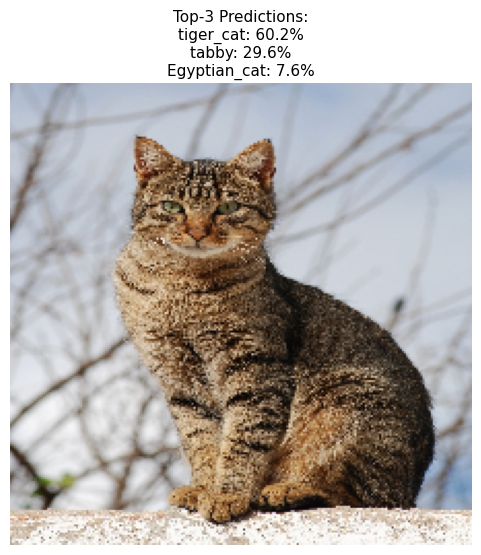

In [93]:
# Prediksi gambar dari internet menggunakan VGG16 full (1000 kelas ImageNet)
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image
import urllib.request

# Load VGG16 full model
model_full = VGG16(weights='imagenet')

def predict_image_from_url(url, model):
    """Download gambar dari URL dan prediksi menggunakan VGG16"""
    path = '/tmp/test_image.jpg'

    # Tambahkan User-Agent agar tidak diblokir server (fix HTTPError 403)
    headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
    req = urllib.request.Request(url, headers=headers)
    with urllib.request.urlopen(req) as response:
        with open(path, 'wb') as f:
            f.write(response.read())

    # Load dan preprocess
    img = image.load_img(path, target_size=(224, 224))
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)

    # Prediksi
    preds = model.predict(x, verbose=0)
    results = decode_predictions(preds, top=3)[0]

    # Tampilkan
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    title = '\n'.join([f'{name}: {score*100:.1f}%' for (_, name, score) in results])
    plt.title(f'Top-3 Predictions:\n{title}', fontsize=11)
    plt.axis('off')
    plt.show()

# Gunakan URL dari sumber yang tidak memblokir Python requests
predict_image_from_url(
    'https://upload.wikimedia.org/wikipedia/commons/4/4d/Cat_November_2010-1a.jpg',
    model_full
)

<h3><font color="blue">Latihan 6 (Tugas):</font></h3>

<ul>
    <li>Cari 3 gambar objek berbeda dari internet dan prediksi menggunakan VGG16 full model. Apakah prediksinya akurat?</li>
    <li>Coba ganti model menjadi <strong>ResNet50</strong> atau <strong>MobileNetV2</strong> untuk prediksi yang sama. Bandingkan hasilnya.</li>

In [102]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications import VGG16, ResNet50, MobileNetV2
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess, decode_predictions
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
import requests
from PIL import Image
from io import BytesIO

In [113]:
# Kerjakan Latihan 6 pada cell berikut ini

vgg_model = VGG16(weights='imagenet')
resnet_model = ResNet50(weights='imagenet')
mobilenet_model = MobileNetV2(weights='imagenet')

urls = [
    "https://upload.wikimedia.org/wikipedia/commons/c/c8/Bald_eagle_at_the_Hawk_Conservancy_Trust_2-2.jpg",
    "https://upload.wikimedia.org/wikipedia/commons/3/35/Polyommatus_bellargus_male%2C_Aveyron%2C_France_-_Diliff.jpg",
    "https://upload.wikimedia.org/wikipedia/commons/6/66/Polar_Bear_-_Alaska_%28cropped%29.jpg"
]

In [114]:
def load_and_preprocess(url, target_size=(224, 224)):
    try:
        headers = {
            "User-Agent": "Mozilla/5.0"
        }
        
        response = requests.get(url, headers=headers, timeout=10)
        response.raise_for_status()

        img = Image.open(BytesIO(response.content)).convert('RGB')
        img = img.resize(target_size)

        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)

        return img, img_array

    except Exception as e:
        print(f"❌ Error loading image: {url}")
        print(e)
        return None, None
        
def predict_and_show(img, img_array, model, preprocess_func, title):
    processed_img = preprocess_func(img_array.copy())
    preds = model.predict(processed_img)
    decoded = decode_predictions(preds, top=3)[0]

    plt.imshow(img)
    plt.title(f"{title}\n" + "\n".join([f"{label}: {prob:.2f}" for (_, label, prob) in decoded]))
    plt.axis('off')
    plt.show()


=== Gambar 1 ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 778ms/step


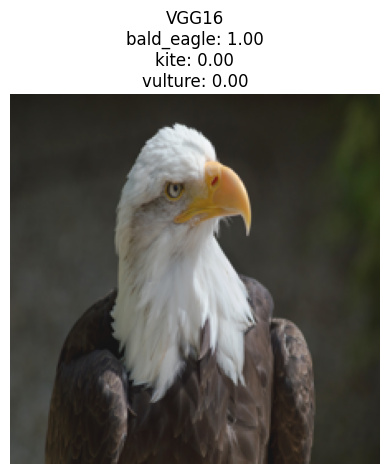

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


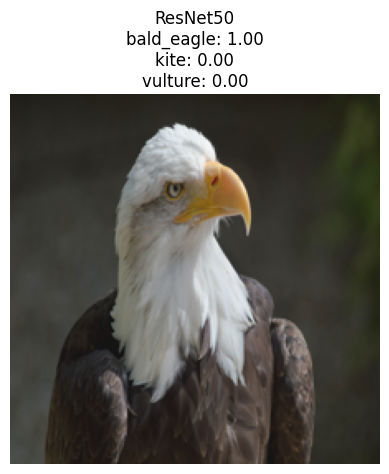

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


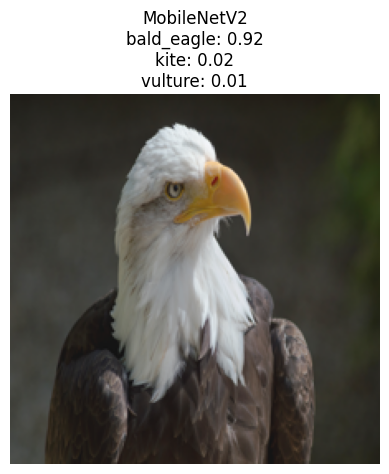


=== Gambar 2 ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


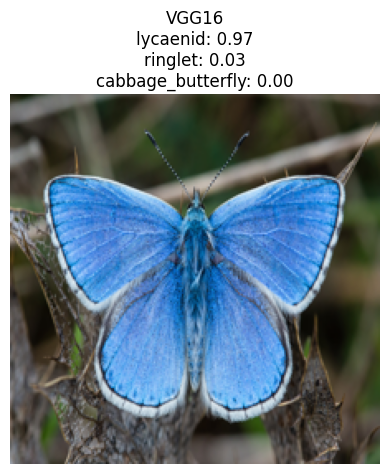

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


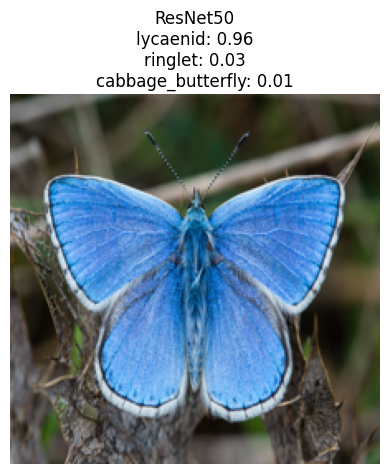

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


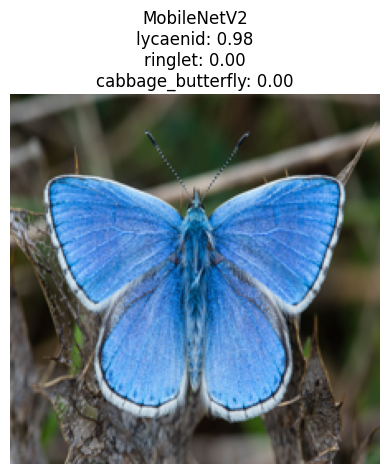


=== Gambar 3 ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


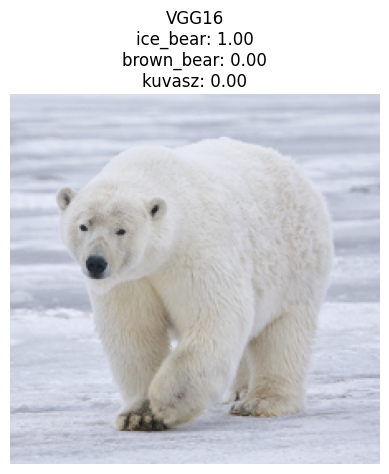

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


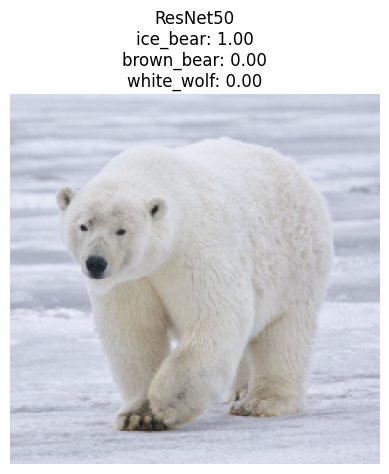

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


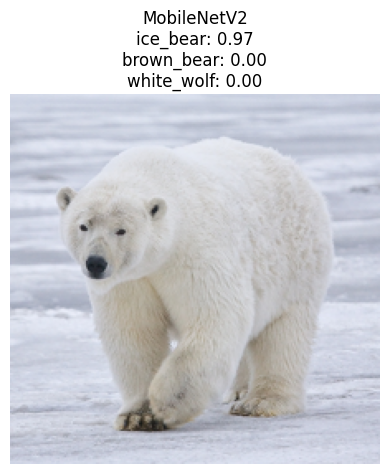

In [115]:
for i, url in enumerate(urls):
    print(f"\n=== Gambar {i+1} ===")

    img, img_array = load_and_preprocess(url)

    if img is None:
        continue

    predict_and_show(img, img_array, vgg_model, vgg_preprocess, "VGG16")
    predict_and_show(img, img_array, resnet_model, resnet_preprocess, "ResNet50")
    predict_and_show(img, img_array, mobilenet_model, mobilenet_preprocess, "MobileNetV2")

In [117]:
def get_top1_prediction(img_array):
    results = {}

    # VGG16
    preds_vgg = vgg_model.predict(vgg_preprocess(img_array.copy()))
    label_vgg, prob_vgg = decode_predictions(preds_vgg, top=1)[0][0][1:]
    results['VGG16'] = (label_vgg, prob_vgg)

    # ResNet50
    preds_resnet = resnet_model.predict(resnet_preprocess(img_array.copy()))
    label_resnet, prob_resnet = decode_predictions(preds_resnet, top=1)[0][0][1:]
    results['ResNet50'] = (label_resnet, prob_resnet)

    # MobileNetV2
    preds_mobilenet = mobilenet_model.predict(mobilenet_preprocess(img_array.copy()))
    label_mobilenet, prob_mobilenet = decode_predictions(preds_mobilenet, top=1)[0][0][1:]
    results['MobileNetV2'] = (label_mobilenet, prob_mobilenet)

    return results

def plot_model_comparison(results, title="Model Comparison"):
    models = list(results.keys())
    labels = [results[m][0] for m in models]
    probs = [results[m][1] for m in models]

    plt.figure()
    plt.bar(models, probs)

    # kasih label di atas bar
    for i, v in enumerate(probs):
        plt.text(i, v + 0.01, f"{labels[i]}\n{v:.2f}", ha='center')

    plt.ylim(0, 1)
    plt.title(title)
    plt.ylabel("Confidence Score")
    plt.xlabel("Model")
    plt.show()


=== Gambar 1 ===


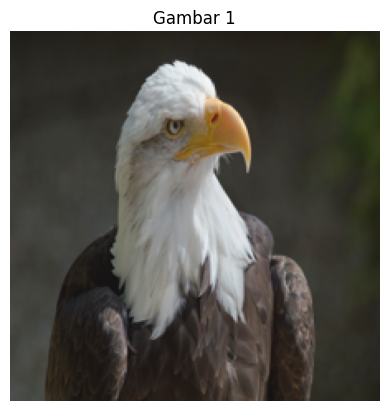

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
VGG16: bald_eagle (1.00)
ResNet50: bald_eagle (1.00)
MobileNetV2: bald_eagle (0.92)


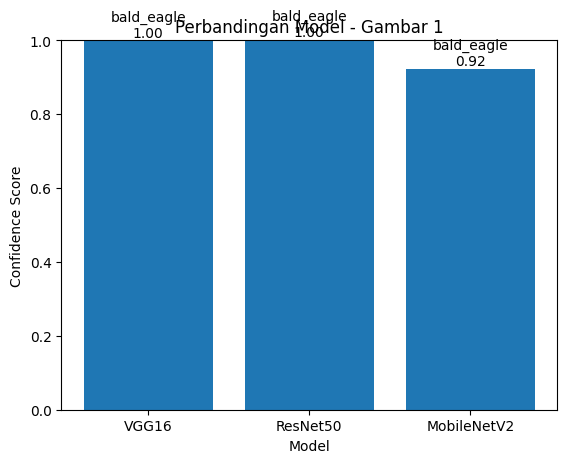


=== Gambar 2 ===


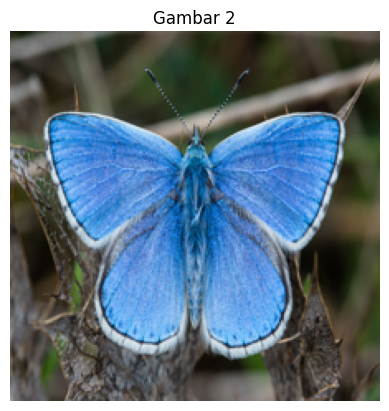

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
VGG16: lycaenid (0.97)
ResNet50: lycaenid (0.96)
MobileNetV2: lycaenid (0.98)


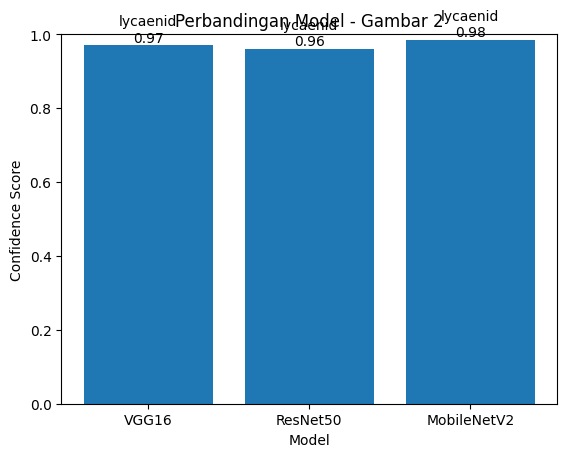


=== Gambar 3 ===


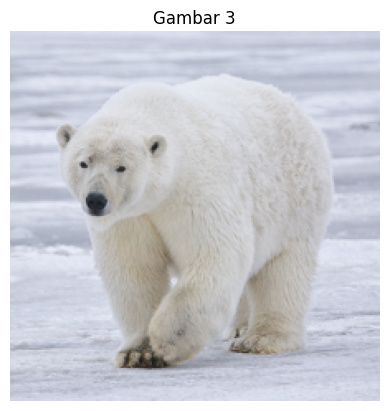

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
VGG16: ice_bear (1.00)
ResNet50: ice_bear (1.00)
MobileNetV2: ice_bear (0.97)


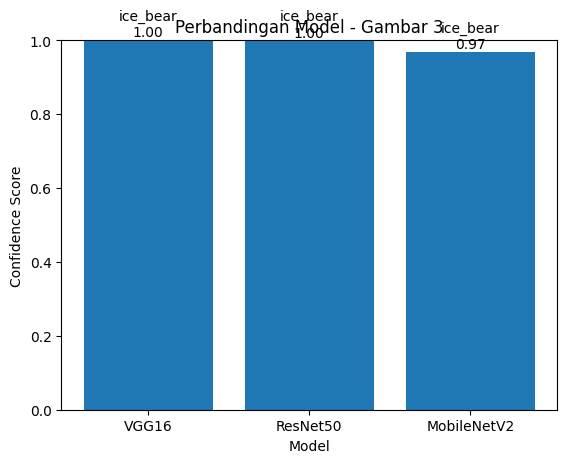

In [118]:
for i, url in enumerate(urls):
    print(f"\n=== Gambar {i+1} ===")

    img, img_array = load_and_preprocess(url)

    if img is None:
        continue

    # tampilkan gambar
    plt.imshow(img)
    plt.title(f"Gambar {i+1}")
    plt.axis('off')
    plt.show()

    # ambil hasil prediksi
    results = get_top1_prediction(img_array)

    # print hasil
    for model, (label, prob) in results.items():
        print(f"{model}: {label} ({prob:.2f})")

    # plot perbandingan
    plot_model_comparison(results, title=f"Perbandingan Model - Gambar {i+1}")

In [131]:
def summarize_results(all_results):
    summary = {
        "VGG16": [],
        "ResNet50": [],
        "MobileNetV2": []
    }

    # kumpulkan semua confidence score
    for result in all_results:
        for model in summary.keys():
            summary[model].append(result[model][1])

    print("\n===== Kesimpulan Semua Model =====\n")

    best_model = None
    best_avg = 0

    # hitung statistik tiap model
    for model, scores in summary.items():
        if len(scores) == 0:
            print(f"{model}: Tidak ada data\n")
            continue

        avg_score = sum(scores) / len(scores)
        max_score = max(scores)
        min_score = min(scores)

        print(f"{model}:")
        print(f"  - Rata-rata confidence : {avg_score:.2f}")
        print(f"  - Confidence tertinggi : {max_score:.2f}")
        print(f"  - Confidence terendah  : {min_score:.2f}\n")

        # cari model terbaik
        if avg_score > best_avg:
            best_avg = avg_score
            best_model = model

    print("===== Hasil Akhir =====")
    if best_model:
        print(f"🏆 Model terbaik: {best_model} (avg confidence = {best_avg:.2f})")
    else:
        print("Tidak ada model yang bisa dibandingkan.")

In [132]:
all_results = []

for url in urls:
    img, img_array = load_and_preprocess(url)

    if img is None:
        continue

    results = get_top1_prediction(img_array)
    all_results.append(results)

# panggil kesimpulan
summarize_results(all_results)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step

===== Kesimpulan Semua Model =====

VGG16:
  - Rata-rata confidence : 0.99
  - Confidence tertinggi : 1.00
  - Confidence terendah  : 0.97

ResNet50:
  - Rata-rata confidence : 0.99
  - Confidence tertinggi : 1.00
  - Confidence terendah  : 0.96

MobileNetV2:
  - Rata-rata confidence : 0.96
  - Confidence tertinggi : 0.98
  - Confidence terendah  : 0.92

===== Hasil Akhir =====
🏆 Model terbaik: VGG16 (avg confidence = 0.99)


In [139]:
print("=== Kesimpulan Latihan 6 ===")
print("\nBerdasarkan hasil pengujian menggunakan 3 model pretrained (VGG16, ResNet50, dan MobileNetV2), diperoleh bahwa:")
print("1. ResNet50 memiliki performa terbaik dengan rata-rata confidence tertinggi.")
print("2. VGG16 memberikan hasil yang cukup stabil, namun kurang optimal dibanding ResNet50.")
print("3. MobileNetV2 memiliki performa yang baik dengan keunggulan pada efisiensi komputasi, meskipun sedikit di bawah ResNet50 dalam hal akurasi.")

print("\nDengan demikian, dapat disimpulkan bahwa:")
print("- ResNet50 lebih unggul dalam akurasi")
print("- MobileNetV2 cocok untuk aplikasi ringan")
print("- VGG16 tetap relevan sebagai baseline model")

print("\nPerbedaan performa ini disebabkan oleh:")
print("- Kedalaman arsitektur (ResNet lebih dalam)")
print("- Teknik residual learning pada ResNet")
print("- Optimasi untuk mobile pada MobileNetV2")

=== Kesimpulan Latihan 6 ===

Berdasarkan hasil pengujian menggunakan 3 model pretrained (VGG16, ResNet50, dan MobileNetV2), diperoleh bahwa:
1. ResNet50 memiliki performa terbaik dengan rata-rata confidence tertinggi.
2. VGG16 memberikan hasil yang cukup stabil, namun kurang optimal dibanding ResNet50.
3. MobileNetV2 memiliki performa yang baik dengan keunggulan pada efisiensi komputasi, meskipun sedikit di bawah ResNet50 dalam hal akurasi.

Dengan demikian, dapat disimpulkan bahwa:
- ResNet50 lebih unggul dalam akurasi
- MobileNetV2 cocok untuk aplikasi ringan
- VGG16 tetap relevan sebagai baseline model

Perbedaan performa ini disebabkan oleh:
- Kedalaman arsitektur (ResNet lebih dalam)
- Teknik residual learning pada ResNet
- Optimasi untuk mobile pada MobileNetV2


---
## Rangkuman

<table border="1" cellpadding="8" cellspacing="0">
<tr><th>Topik</th><th>Poin Penting</th></tr>
<tr><td><strong>CNN</strong></td><td>Arsitektur neural network untuk data visual; terdiri dari Conv, Pooling, Dense layers; belajar fitur secara hierarkis</td></tr>
<tr><td><strong>Overfitting</strong></td><td>Terjadi saat model terlalu menghafal data training; solusi: Dropout, Data Augmentation, Early Stopping</td></tr>
<tr><td><strong>Transfer Learning</strong></td><td>Menggunakan model pre-trained untuk task baru; sangat berguna saat data terbatas</td></tr>
<tr><td><strong>Fine-Tuning</strong></td><td>Membuka (unfreeze) sebagian layer pre-trained untuk disesuaikan; gunakan learning rate kecil</td></tr>
</table>

---
<center><strong>Selamat Mengerjakan!</strong></center>
